# When Filling the Gaps Isn't Neutral: Auditing the Fairness Impact of Missing-Data Imputation

**Author:** Nuno Dos Santos Moreira — Master in Artificial Intelligence, FCUP

This notebook reproduces **every number, table and figure** of the revised report. It studies how
missing data, and the way we fill them in (imputation), change the *group fairness* of a downstream
classifier.

### Research questions
* **RQ1 (mechanism).** How do the missingness mechanism (MCAR, MAR, MNAR) and the missingness rate change the
  group fairness of a downstream classifier, relative to the same classifier trained on complete data?
* **RQ2 (imputation method).** Do mean, K-nearest-neighbours (KNN) and MICE imputation differ in their fairness
  impact, and is any method consistently better or worse across datasets?
* **RQ3 (group-dependent missingness).** When values are missing more often for a protected group, does
  imputation widen or narrow fairness gaps compared with group-neutral (MCAR) missingness at the same overall
  rate, and who bears the cost?

### Design in one paragraph
Five public fairness benchmarks (Adult, COMPAS, German Credit, Credit-card Default, Law School), each with two
sensitive attributes. For every repetition (seed) the data are **split first** (70/30, stratified on label × group);
missing values are then injected into four numeric features of both splits with a **calibrated** mechanism
(MCAR, MAR, MNAR or group-dependent) so that the realised rate equals the target rate (5 %, 15 % or 30 %).
Scaler, encoder, imputer and classifier are **fit on the training split only**. Every condition is compared
with a **complete-data baseline on the same split**, so all effects are paired differences.
Stage 1 (rate study) uses 10 seeds for every rate; Stage 2 adds 10 more seeds at the selected rate,
giving **20 repetitions** for the main analysis (mean ± standard deviation reported everywhere).

### How to run
`pip install -r requirements.txt`, then *Run All* (step-by-step instructions in the README). The raw datasets are
read from `data/` (downloaded once if missing) and checked against MD5 checksums. Each (stage, dataset, seed)
result is cached in `results/cache/`: with the cache present the notebook runs in under a minute; delete that
folder to recompute everything (about 4.3 CPU-hours, dominated by KNN imputation on Adult; parallelised over all
cores).

### What changed with respect to the previous version (`new_version3.ipynb`)
| Issue in the previous version | Fix in this version |
|---|---|
| Report covered Adult only; COMPAS ran in the notebook with sex only, recidivism as the positive class and a race flag that was 0 for everyone (`race == 'White'`, but COMPAS codes white defendants as `'Caucasian'`) | Five datasets (Adult, COMPAS, German, Credit, Law), all analysed and reported; COMPAS uses race and sex, favourable outcome = no recidivism |
| Imputers fit with `fit_transform` on the whole dataset before the split (leakage) | Split first; scaler, encoder, imputer and model are fit on the training split only |
| KNN imputation on unscaled data | Numeric features standardised (fit on train) before KNN/MICE |
| No complete-data baseline | Baseline without missing values on the same split, in every repetition; all effects are paired differences |
| One run (seed 42) per condition | Stage 1: 10 seeds per rate; Stage 2: 20 seeds at the selected rate; mean ± SD everywhere |
| One perturbed column (age, 1.8 % of cells) | Four numeric features per dataset |
| Realised rates differed by mechanism (30/9/17.5/25 %) | Intercepts calibrated so every mechanism removes exactly the target share |
| MAR driven by the label-encoded `workclass` code | MAR driven by a meaningful, fully observed numeric feature (e.g. age) |
| Only `sex_binary` as sensitive attribute | Two sensitive attributes per dataset (sex, race, age, marital status) + intersectional subgroups |
| `'?'` values silently kept (`na_values=' ?'` + `skipinitialspace=True`) | `na_values='?'`; incomplete rows removed (48,842 → 45,222) |
| t-tests/ANOVA on 3–4 non-independent numbers | Wilcoxon signed-rank over seeds, Friedman tests, Benjamini–Hochberg correction |
| Rate fixed at 30 % without justification | Rate study at 5 %, 15 %, 30 % and a pre-specified selection rule |
| Analyses in the notebook but not in the report | Every analysis kept here (tests, robustness, feature importance, cost–benefit) is exported to the report |

## 0. Setup

In [1]:
import hashlib
import time
import warnings
from dataclasses import dataclass
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from scipy import special          # special.expit = logistic function (module reference keeps it picklable)
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (activates IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---------------- experimental configuration ----------------
SEEDS_STAGE1 = list(range(0, 10))    # rate study: 10 repetitions for every rate
SEEDS_STAGE2 = list(range(10, 20))   # 10 extra repetitions at the selected rate (20 in total)
RATES = [0.05, 0.15, 0.30]           # target share of missing values in each perturbed feature
MECHANISMS = ["MCAR", "MAR", "MNAR", "GD"]   # GD = group-dependent missingness (RQ3)
IMPUTERS = ["Mean", "KNN", "MICE"]
MODELS = ["LR", "HGB"]               # LR = audited model; HGB = gradient boosting (robustness check)
TEST_SIZE = 0.30
MASK_STRENGTH = 2.0                  # MAR/MNAR slope, in log-odds per standardised rank
GD_RATIO = 3.0                       # protected : reference missingness ratio under GD
N_JOBS = -1                          # use all CPU cores

DATA_DIR, RESULTS_DIR = Path("data"), Path("results")
CACHE_DIR, FIG_DIR, TAB_DIR = RESULTS_DIR / "cache", Path("figures"), Path("tables")
for d in (DATA_DIR, CACHE_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 1. Datasets

All five datasets are standard fairness benchmarks surveyed by Le Quy et al. (2022). Raw files are fetched from
stable GitHub mirrors (the UCI copies are identical; e.g. `adult-all.csv` = `adult.data` + `adult.test`,
48,842 rows) and verified with MD5 checksums so that every run uses byte-identical data.

| Dataset | Favourable outcome (y = 1) | Sensitive attributes (protected group) | Perturbed numeric features | MAR driver |
|---|---|---|---|---|
| Adult | income > 50K | **sex** (female), race (non-White) | education_num, capital_gain, capital_loss, hours_per_week | age |
| COMPAS | no recidivism within 2 years | **race** (non-Caucasian), sex (male) | priors_count, juv_fel_count, juv_misd_count, juv_other_count | age |
| German | good credit risk | **sex** (female), age (≤ 25) | credit_amount, installment_rate, residence_since, existing_credits | duration |
| Credit | no default next month | **sex** (female), marriage (not married) | LIMIT_BAL, PAY_0, BILL_AMT1, PAY_AMT1 | AGE |
| Law | passes the bar exam | **race** (non-White), sex (female) | lsat, ugpa, zfygpa, fam_inc | tier |

The **bold** attribute is the *primary* one: it is the target of group-dependent missingness and of the main
fairness analysis. Sensitive attributes are **not** used as model inputs (fairness through unawareness, as in
most legal settings); they are used only to generate group-dependent missingness and to evaluate fairness.
Rows with genuinely missing values (`?` in Adult) are removed so that a complete ground truth exists — the
previous version's loader failed to detect them (`na_values=' ?'` never matches once `skipinitialspace=True`).

In [2]:
DATA_SOURCES = {
    "adult": ("adult-all.csv",
              "https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv",
              "779a6204aa629e559c8f48d0897526cf"),
    "compas": ("compas-scores-two-years.csv",
               "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv",
               "9165d40c400bba93a8cffece2b74622b"),
    "german": ("german.csv",
               "https://raw.githubusercontent.com/jbrownlee/Datasets/master/german.csv",
               "8e2c6d456b3cda1f273bfbbbd73ece6c"),
    "credit": ("credit-card-clients.csv",
               "https://raw.githubusercontent.com/tailequy/fairness_dataset/main/experiments/data/credit-card-clients.csv",
               "b4c032de2325e194778792f7e7610d06"),
    "law": ("law_school_clean.csv",
            "https://raw.githubusercontent.com/tailequy/fairness_dataset/main/experiments/data/law_school_clean.csv",
            "8190cf1a6ec36e8321feae9c5a111ad2"),
}


def fetch(key: str) -> Path:
    """Download a raw file once (cached in ./data) and verify its MD5 checksum."""
    fname, url, md5 = DATA_SOURCES[key]
    path = DATA_DIR / fname
    if not path.exists():
        urlretrieve(url, path)
    digest = hashlib.md5(path.read_bytes()).hexdigest()
    if digest != md5:
        raise ValueError(f"Checksum mismatch for {fname}: got {digest}, expected {md5}")
    return path


@dataclass
class DatasetSpec:
    name: str
    data: pd.DataFrame      # complete data: features + target + protected-group indicators
    target: str             # binary, 1 = favourable outcome
    num_cols: list
    cat_cols: list
    miss_cols: list         # numeric features that receive synthetic missingness
    mar_driver: str         # fully observed feature that drives MAR missingness
    sensitive: dict         # attribute -> (indicator column, protected label, reference label); primary first
    favourable: str
    n_raw: int

    @property
    def feature_cols(self):
        return self.num_cols + self.cat_cols

    @property
    def primary(self):
        return next(iter(self.sensitive))


def load_adult() -> DatasetSpec:
    cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation",
            "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week",
            "native_country", "income"]
    raw = pd.read_csv(fetch("adult"), header=None, names=cols, skipinitialspace=True, na_values="?")
    df = raw.dropna().copy()                                    # 48,842 -> 45,222 complete rows
    df["income"] = df["income"].str.rstrip(".")
    df["y"] = (df["income"] == ">50K").astype(int)
    df["A_sex"] = (df["sex"] == "Female").astype(int)
    df["A_race"] = (df["race"] != "White").astype(int)
    df["native_country"] = np.where(df["native_country"] == "United-States", "United-States", "Other")
    num = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
    cat = ["workclass", "marital_status", "occupation", "relationship", "native_country"]
    df[num] = df[num].astype(float)          # fnlwgt (sampling weight) and education (= education_num) dropped
    return DatasetSpec("Adult", df[num + cat + ["y", "A_sex", "A_race"]].reset_index(drop=True), "y", num, cat,
                       ["education_num", "capital_gain", "capital_loss", "hours_per_week"], "age",
                       {"sex": ("A_sex", "Female", "Male"), "race": ("A_race", "Non-White", "White")},
                       "income >50K", len(raw))


def load_compas() -> DatasetSpec:
    raw = pd.read_csv(fetch("compas"))
    df = raw[raw["days_b_screening_arrest"].between(-30, 30) & (raw["is_recid"] != -1)
             & (raw["c_charge_degree"] != "O") & (raw["score_text"] != "N/A")].copy()   # ProPublica filter
    df["y"] = 1 - df["two_year_recid"]                           # favourable: no recidivism in two years
    df["A_race"] = (df["race"] != "Caucasian").astype(int)       # note: COMPAS uses 'Caucasian', not 'White'
    df["A_sex"] = (df["sex"] == "Male").astype(int)
    num = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"]
    cat = ["c_charge_degree"]
    df[num] = df[num].astype(float)
    return DatasetSpec("COMPAS", df[num + cat + ["y", "A_race", "A_sex"]].reset_index(drop=True), "y", num, cat,
                       ["priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"], "age",
                       {"race": ("A_race", "Non-Caucasian", "Caucasian"), "sex": ("A_sex", "Male", "Female")},
                       "no two-year recidivism", len(raw))


def load_german() -> DatasetSpec:
    cols = ["checking_status", "duration", "credit_history", "purpose", "credit_amount", "savings",
            "employment", "installment_rate", "personal_status", "other_debtors", "residence_since",
            "property", "age", "other_installment_plans", "housing", "existing_credits", "job",
            "num_dependents", "telephone", "foreign_worker", "class"]
    df = pd.read_csv(fetch("german"), header=None, names=cols)
    n_raw = len(df)
    df["y"] = (df["class"] == 1).astype(int)                     # 1 = good credit risk
    df["A_sex"] = df["personal_status"].isin(["A92", "A95"]).astype(int)   # female applicants
    df["A_age"] = (df["age"] <= 25).astype(int)                  # young applicants
    num = ["duration", "credit_amount", "installment_rate", "residence_since", "existing_credits",
           "num_dependents"]
    cat = ["checking_status", "credit_history", "purpose", "savings", "employment", "other_debtors",
           "property", "other_installment_plans", "housing", "job", "telephone", "foreign_worker"]
    df[num] = df[num].astype(float)          # personal_status and age are sensitive -> not model inputs
    return DatasetSpec("German", df[num + cat + ["y", "A_sex", "A_age"]].reset_index(drop=True), "y", num, cat,
                       ["credit_amount", "installment_rate", "residence_since", "existing_credits"], "duration",
                       {"sex": ("A_sex", "Female", "Male"), "age": ("A_age", "Age<=25", "Age>25")},
                       "good credit risk", n_raw)


def load_credit() -> DatasetSpec:
    df = pd.read_csv(fetch("credit"))
    n_raw = len(df)
    df["y"] = (df["default payment"] == 0).astype(int)          # favourable: no default next month
    df["A_sex"] = (df["SEX"] == 2).astype(int)                  # female
    df["A_marriage"] = (df["MARRIAGE"] != 1).astype(int)        # not married
    df["EDUCATION"] = df["EDUCATION"].astype(str)
    num = (["LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
           + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)])
    cat = ["EDUCATION"]
    df[num] = df[num].astype(float)
    return DatasetSpec("Credit", df[num + cat + ["y", "A_sex", "A_marriage"]].reset_index(drop=True), "y", num,
                       cat, ["LIMIT_BAL", "PAY_0", "BILL_AMT1", "PAY_AMT1"], "AGE",
                       {"sex": ("A_sex", "Female", "Male"), "marriage": ("A_marriage", "Not married", "Married")},
                       "no default", n_raw)


def load_law() -> DatasetSpec:
    df = pd.read_csv(fetch("law"))
    n_raw = len(df)
    df["y"] = df["pass_bar"].astype(int)
    df["A_race"] = (df["race"] != "White").astype(int)
    df["A_sex"] = (df["male"] == 0).astype(int)
    df["fulltime"] = df["fulltime"].astype(int).astype(str)
    num = ["lsat", "ugpa", "zfygpa", "zgpa", "decile1b", "decile3", "fam_inc", "tier"]
    cat = ["fulltime"]
    df[num] = df[num].astype(float)
    return DatasetSpec("Law", df[num + cat + ["y", "A_race", "A_sex"]].reset_index(drop=True), "y", num, cat,
                       ["lsat", "ugpa", "zfygpa", "fam_inc"], "tier",
                       {"race": ("A_race", "Non-White", "White"), "sex": ("A_sex", "Female", "Male")},
                       "bar passage", n_raw)


LOADERS = {"Adult": load_adult, "COMPAS": load_compas, "German": load_german,
           "Credit": load_credit, "Law": load_law}

In [3]:
SPECS = {name: loader() for name, loader in LOADERS.items()}


def describe(spec: DatasetSpec) -> dict:
    D = spec.data
    row = {"dataset": spec.name, "raw rows": spec.n_raw, "rows used": len(D),
           "features": len(spec.feature_cols), "numeric": len(spec.num_cols),
           "P(y=1)": round(D[spec.target].mean(), 3)}
    for role, (attr, (col, prot, ref)) in zip(("primary", "secondary"), spec.sensitive.items()):
        rate_p, rate_r = D.loc[D[col] == 1, spec.target].mean(), D.loc[D[col] == 0, spec.target].mean()
        row[f"{role} attribute"] = f"{attr}: {prot} ({D[col].mean():.0%})"
        row[f"{role} P(y=1) prot/ref"] = f"{rate_p:.2f}/{rate_r:.2f}"
    return row


dataset_table = pd.DataFrame([describe(s) for s in SPECS.values()])
dataset_table.to_csv(TAB_DIR / "datasets.csv", index=False)
dataset_table

,dataset,raw rows,rows used,features,numeric,P(y=1),primary attribute,primary P(y=1) prot/ref,secondary attribute,secondary P(y=1) prot/ref
0,Adult,48842,45222,10,5,0.248,sex: Female (32%),0.11/0.31,race: Non-White (14%),0.16/0.26
1,COMPAS,7214,6172,6,5,0.545,race: Non-Caucasian (66%),0.51/0.61,sex: Male (81%),0.52/0.65
2,German,1000,1000,18,6,0.700,sex: Female (31%),0.65/0.72,age: Age<=25 (19%),0.58/0.73
3,Credit,30000,30000,21,20,0.779,sex: Female (60%),0.79/0.76,marriage: Not married (54%),0.79/0.77
4,Law,20798,20798,9,8,0.890,race: Non-White (16%),0.72/0.92,sex: Female (44%),0.88/0.90


## 2. Controlled missingness generation

Missing values are injected into the four perturbed numeric features of each dataset (table above), separately
in the training and the test split (both splits contain missing values, as they would at deployment). For each
row *i* and perturbed feature *j* we compute a removal probability $p_{ij}$ and delete the value when
$U_{ij} < p_{ij}$, with $U_{ij}\sim\mathcal{U}(0,1)$:

| Mechanism | Removal probability $p_{ij}$ | Interpretation |
|---|---|---|
| MCAR | $r$ | independent of all data |
| MAR | $\sigma(\alpha + \beta\, z_i^{\text{driver}})$ | depends on a fully observed feature (e.g. age) |
| MNAR | $\sigma(\alpha_j + \beta\, z_{ij})$ | self-masking: larger values are more likely to be missing |
| GD | $3c$ if protected, $c$ otherwise, $c = r/(3w + 1 - w)$ | group-dependent (MAR on the sensitive attribute) |

where $\sigma$ is the logistic function, $z$ is the **standardised rank** of a variable (robust to skewed
features such as capital gains), $\beta = 2$ and $w$ is the share of the protected group. The intercepts
$\alpha$ are **calibrated by bisection** so that the average removal probability equals the target rate $r$
*for every mechanism* — the previous version compared MCAR at 30 % with MAR at 9 %, MNAR at 17.5 % and
group-dependent at 25 %. The same uniform draws $U$ are reused across mechanisms and rates within a seed
(common random numbers), so masks are nested across rates (the 5 % mask ⊂ 15 % mask ⊂ 30 % mask) and
differences between conditions are not blurred by unrelated sampling noise.

In [4]:
def standardized_rank(x) -> np.ndarray:
    r = pd.Series(np.asarray(x, dtype=float)).rank(method="average").to_numpy()
    return (r - r.mean()) / r.std()


def calibrate_intercept(score: np.ndarray, rate: float) -> float:
    """Bisection for alpha such that mean(sigmoid(alpha + score)) equals the target rate."""
    lo, hi = -30.0, 30.0
    for _ in range(80):
        mid = (lo + hi) / 2
        if special.expit(mid + score).mean() > rate:
            hi = mid
        else:
            lo = mid
    return (lo + hi) / 2


def missing_probabilities(X: pd.DataFrame, spec: DatasetSpec, mechanism: str, rate: float,
                          a_primary: np.ndarray) -> np.ndarray:
    """n x k matrix with the probability that value j of row i is removed."""
    n, k = len(X), len(spec.miss_cols)
    if mechanism == "MCAR":
        return np.full((n, k), rate)
    if mechanism == "MAR":
        s = MASK_STRENGTH * standardized_rank(X[spec.mar_driver])
        return np.repeat(special.expit(calibrate_intercept(s, rate) + s)[:, None], k, axis=1)
    if mechanism == "MNAR":
        P = np.empty((n, k))
        for j, col in enumerate(spec.miss_cols):
            s = MASK_STRENGTH * standardized_rank(X[col])
            P[:, j] = special.expit(calibrate_intercept(s, rate) + s)
        return P
    if mechanism == "GD":
        w = a_primary.mean()
        base = rate / (GD_RATIO * w + (1 - w))
        assert GD_RATIO * base < 1, "group-dependent removal probability would exceed 1"
        return np.repeat(np.where(a_primary == 1, GD_RATIO * base, base)[:, None], k, axis=1)
    raise ValueError(f"unknown mechanism {mechanism}")


def apply_missingness(X: pd.DataFrame, spec: DatasetSpec, mechanism: str, rate: float,
                      a_primary: np.ndarray, U: np.ndarray):
    """Return a copy of X with values removed where U < p, and the boolean mask."""
    M = U < missing_probabilities(X, spec, mechanism, rate, a_primary)
    Xm = X.copy()
    vals = Xm[spec.miss_cols].to_numpy(dtype=float, copy=True)
    vals[M] = np.nan
    Xm[spec.miss_cols] = vals
    return Xm, M

**Sanity check.** Realised missing rates on Adult (training split of seed 0) for every mechanism and rate.
Under GD the protected group (women) has three times the rate of the reference group while the overall
rate still equals the target.

In [5]:
def realised_rates(spec: DatasetSpec, seed: int = 0) -> pd.DataFrame:
    D = spec.data
    a = D[spec.sensitive[spec.primary][0]].to_numpy()
    U = np.random.default_rng(seed).random((len(D), len(spec.miss_cols)))
    rows = []
    for mech in MECHANISMS:
        for r in RATES:
            _, M = apply_missingness(D[spec.feature_cols], spec, mech, r, a, U)
            rows.append({"mechanism": mech, "target rate": r, "realised (all)": M.mean(),
                         "realised (protected)": M[a == 1].mean(), "realised (reference)": M[a == 0].mean(),
                         "rows with >=1 missing": M.any(axis=1).mean()})
    return pd.DataFrame(rows).round(3)


realised_rates(SPECS["Adult"])

,mechanism,target rate,realised (all),realised (protected),realised (reference),rows with >=1 missing
0,MCAR,0.05,0.050,0.049,0.050,0.185
1,MCAR,0.15,0.151,0.151,0.151,0.480
2,MCAR,0.30,0.300,0.298,0.300,0.761
3,MAR,0.05,0.050,0.045,0.052,0.159
4,MAR,0.15,0.150,0.138,0.157,0.353
5,MAR,0.30,0.300,0.272,0.313,0.543
6,MNAR,0.05,0.050,0.036,0.057,0.183
7,MNAR,0.15,0.150,0.123,0.163,0.463
8,MNAR,0.30,0.300,0.265,0.317,0.744
9,GD,0.05,0.050,0.090,0.031,0.181


## 3. Leakage-free pipeline

For every repetition: **split → inject missingness → fit scaler/encoder/imputer on the training split →
transform the test split with the fitted objects → train the classifier → evaluate on the test split.**
Numeric features are standardised *before* imputation (the scaler ignores missing values when fitting), so KNN
distances are not dominated by large-scale features; categorical features are one-hot encoded and serve as
predictors for KNN and MICE.

* **Mean** — `SimpleImputer(strategy="mean")`.
* **KNN** — `KNNImputer(n_neighbors=5)` on standardised + one-hot features (float32 for speed).
* **MICE** — `IterativeImputer(max_iter=10)` with Bayesian ridge regressions (chained equations; single imputation).
* **LR** — `LogisticRegression` (the audited model); **HGB** — `HistGradientBoostingClassifier` (robustness check).

In [6]:
def make_imputer(name: str, seed: int):
    if name == "Mean":
        return SimpleImputer(strategy="mean")
    if name == "KNN":
        return KNNImputer(n_neighbors=5)
    if name == "MICE":
        return IterativeImputer(max_iter=10, random_state=seed, skip_complete=True)
    raise ValueError(name)


def make_model(name: str, seed: int):
    if name == "LR":
        return LogisticRegression(max_iter=2000)
    if name == "HGB":
        return HistGradientBoostingClassifier(random_state=seed)
    raise ValueError(name)


def encode_impute(spec: DatasetSpec, Xtr: pd.DataFrame, Xte: pd.DataFrame, imputer_name=None, seed=0):
    """Fit scaler + one-hot encoder + imputer on the training split only, then transform both splits."""
    pre = ColumnTransformer([
        ("num", StandardScaler(), spec.num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), spec.cat_cols)])
    Ztr, Zte = pre.fit_transform(Xtr), pre.transform(Xte)
    if imputer_name is not None:
        if imputer_name == "KNN":
            Ztr, Zte = Ztr.astype(np.float32), Zte.astype(np.float32)
        imputer = make_imputer(imputer_name, seed)
        Ztr = imputer.fit_transform(Ztr).astype(float)
        Zte = imputer.transform(Zte).astype(float)
    return Ztr, Zte, pre

## 4. Metrics

The favourable outcome is always coded as 1. For a sensitive attribute with protected group $a=1$ and reference
group $a=0$ (selection rate SR, true/false positive rates TPR/FPR, all on the test split):

* Statistical parity difference $\text{SPD}=\text{SR}_1-\text{SR}_0$ and disparate impact $\text{DIR}=\text{SR}_1/\text{SR}_0$;
* Equal opportunity difference $\text{EOD}=\text{TPR}_1-\text{TPR}_0$;
* Average absolute odds difference $\text{AOD}=\tfrac12(|\text{TPR}_1-\text{TPR}_0|+|\text{FPR}_1-\text{FPR}_0|)$.

Negative SPD/EOD mean the protected group is disadvantaged. The analysis focuses on the **size of the gaps**
$|\text{SPD}|$ and $|\text{EOD}|$ and on their **change relative to the complete-data baseline** of the same
seed: $\Delta|\text{SPD}| = |\text{SPD}_{\text{imputed}}| - |\text{SPD}_{\text{complete}}|$ (positive = less fair).
We also store per-group AUC and calibration-in-the-large, intersectional selection rates, confusion counts,
imputation error by group and the share of the logistic-regression weight placed on the perturbed features.

In [7]:
def _group_rates(y, yhat, m):
    yt, yp = y[m], yhat[m]
    sr = yp.mean() if m.any() else np.nan
    tpr = yp[yt == 1].mean() if (yt == 1).any() else np.nan
    fpr = yp[yt == 0].mean() if (yt == 0).any() else np.nan
    return sr, tpr, fpr


def _safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan


def group_fairness(y, proba, yhat, a) -> dict:
    sr1, tpr1, fpr1 = _group_rates(y, yhat, a == 1)   # protected group
    sr0, tpr0, fpr0 = _group_rates(y, yhat, a == 0)   # reference group
    m1, m0 = a == 1, a == 0
    return {"sr_prot": sr1, "sr_ref": sr0, "tpr_prot": tpr1, "tpr_ref": tpr0, "fpr_prot": fpr1, "fpr_ref": fpr0,
            "spd": sr1 - sr0, "dir": sr1 / sr0 if sr0 > 0 else np.nan, "eod": tpr1 - tpr0, "fprd": fpr1 - fpr0,
            "aod": 0.5 * (abs(tpr1 - tpr0) + abs(fpr1 - fpr0)),
            "acc_prot": (y[m1] == yhat[m1]).mean(), "acc_ref": (y[m0] == yhat[m0]).mean(),
            "auc_prot": _safe_auc(y[m1], proba[m1]), "auc_ref": _safe_auc(y[m0], proba[m0]),
            "cal_prot": proba[m1].mean() - y[m1].mean(), "cal_ref": proba[m0].mean() - y[m0].mean()}


def evaluate_predictions(y, proba, A: dict) -> dict:
    """Performance + fairness for the primary (prefix p_) and secondary (prefix s_) attribute."""
    yhat = (proba >= 0.5).astype(int)
    out = {"acc": accuracy_score(y, yhat), "bal_acc": balanced_accuracy_score(y, yhat),
           "f1": f1_score(y, yhat, zero_division=0), "auc": roc_auc_score(y, proba),
           "tp": int(((y == 1) & (yhat == 1)).sum()), "fp": int(((y == 0) & (yhat == 1)).sum()),
           "tn": int(((y == 0) & (yhat == 0)).sum()), "fn": int(((y == 1) & (yhat == 0)).sum())}
    (a1, v1), (a2, v2) = list(A.items())
    out.update({f"p_{k}": v for k, v in group_fairness(y, proba, yhat, v1).items()})
    out.update({f"s_{k}": v for k, v in group_fairness(y, proba, yhat, v2).items()})
    srs, tprs = [], []
    for g1 in (0, 1):                                  # intersectional subgroups (primary x secondary)
        for g2 in (0, 1):
            m = (v1 == g1) & (v2 == g2)
            sr = yhat[m].mean() if m.sum() >= 20 else np.nan
            pos = m & (y == 1)
            tpr = yhat[pos].mean() if pos.sum() >= 10 else np.nan
            out[f"int_sr_{g1}{g2}"], out[f"int_tpr_{g1}{g2}"] = sr, tpr
            srs.append(sr)
            tprs.append(tpr)
    out["int_sr_gap"] = np.nanmax(srs) - np.nanmin(srs)
    out["int_tpr_gap"] = np.nanmax(tprs) - np.nanmin(tprs)
    return out


def imputation_quality(spec, Xte_true, Zte, pre, Mte, a_te, sd_ref) -> dict:
    """Normalised RMSE and bias of imputed test values (units of the complete-data SD), by group."""
    idx = [spec.num_cols.index(c) for c in spec.miss_cols]
    scaler = pre.named_transformers_["num"]
    imputed = Zte[:, idx] * scaler.scale_[idx] + scaler.mean_[idx]     # back to raw units
    err = (imputed - Xte_true[spec.miss_cols].to_numpy(dtype=float)) / sd_ref
    out = {}
    for tag, rows in (("all", np.ones(len(a_te), bool)), ("prot", a_te == 1), ("ref", a_te == 0)):
        e = err[rows][Mte[rows]]
        out[f"nrmse_{tag}"] = float(np.sqrt(np.mean(e ** 2))) if e.size else np.nan
        out[f"bias_{tag}"] = float(np.mean(e)) if e.size else np.nan
    return out


def lr_weight_on_perturbed(model, pre, spec) -> float:
    """Share of the total |coefficient| mass of the logistic regression placed on the perturbed features."""
    names = pre.get_feature_names_out()
    w = np.abs(model.coef_.ravel())
    on_miss = [n.split("__", 1)[0] == "num" and n.split("__", 1)[1] in spec.miss_cols for n in names]
    return float(w[on_miss].sum() / w.sum())

## 5. Experiment runner

One unit of work = one dataset × one seed. Inside it, the split and the complete-data baseline are shared by all
conditions, and the same missingness mask is shared by the three imputers (paired design). Results are cached
per (stage, dataset, seed) so the notebook can be re-run without recomputation.

In [8]:
def run_dataset_seed(spec: DatasetSpec, seed: int, rates, mechanisms, imputers=IMPUTERS, models=MODELS):
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    D = spec.data
    X, y = D[spec.feature_cols], D[spec.target].to_numpy()
    A = {a: D[col].to_numpy() for a, (col, _, _) in spec.sensitive.items()}
    a_prim = A[spec.primary]
    tr, te = train_test_split(np.arange(len(D)), test_size=TEST_SIZE, random_state=seed,
                              stratify=2 * y + a_prim)                    # stratify on label x primary group
    Xtr, Xte = X.iloc[tr].reset_index(drop=True), X.iloc[te].reset_index(drop=True)
    ytr, yte = y[tr], y[te]
    Ate = {a: v[te] for a, v in A.items()}
    a_tr, a_te = a_prim[tr], a_prim[te]
    sd_ref = Xtr[spec.miss_cols].std().to_numpy()
    attrs = list(spec.sensitive)
    common = {"dataset": spec.name, "seed": seed, "attr_p": attrs[0], "attr_s": attrs[1],
              "n_train": len(tr), "n_test": len(te)}
    rows = []

    def fit_and_score(Ztr, Zte, pre, extra):
        for mname in models:
            t0 = time.perf_counter()
            model = make_model(mname, seed).fit(Ztr, ytr)
            proba = model.predict_proba(Zte)[:, 1]
            rec = {**common, **extra, "model": mname, **evaluate_predictions(yte, proba, Ate),
                   "t_model": time.perf_counter() - t0}
            rec["w_perturbed"] = lr_weight_on_perturbed(model, pre, spec) if mname == "LR" else np.nan
            rows.append(rec)

    # (a) complete-data baseline on the same split
    Ztr, Zte, pre = encode_impute(spec, Xtr, Xte, None)
    fit_and_score(Ztr, Zte, pre, {"mechanism": "Complete", "rate": 0.0, "imputer": "Complete"})

    # (b) missingness -> imputation -> model; uniform draws shared across mechanisms and rates
    ss = np.random.SeedSequence([20260105, seed])
    rng_tr, rng_te = (np.random.default_rng(s) for s in ss.spawn(2))
    Utr = rng_tr.random((len(tr), len(spec.miss_cols)))
    Ute = rng_te.random((len(te), len(spec.miss_cols)))
    for mech in mechanisms:
        for rate in rates:
            Xtr_m, Mtr = apply_missingness(Xtr, spec, mech, rate, a_tr, Utr)
            Xte_m, Mte = apply_missingness(Xte, spec, mech, rate, a_te, Ute)
            info = {"mechanism": mech, "rate": rate, "real_rate_tr": Mtr.mean(), "real_rate_te": Mte.mean(),
                    "real_rate_prot": Mte[a_te == 1].mean(), "real_rate_ref": Mte[a_te == 0].mean(),
                    "cell_rate": Mtr.sum() / (len(tr) * len(spec.feature_cols)),
                    "row_rate": Mtr.any(axis=1).mean()}
            for imp in imputers:
                t0 = time.perf_counter()
                Ztr, Zte, pre = encode_impute(spec, Xtr_m, Xte_m, imp, seed)
                quality = imputation_quality(spec, Xte, Zte, pre, Mte, a_te, sd_ref)
                fit_and_score(Ztr, Zte, pre, {**info, "imputer": imp,
                                              "t_impute": time.perf_counter() - t0, **quality})
    return rows


def run_task(spec: DatasetSpec, seed: int, stage: str, rates, mechanisms) -> pd.DataFrame:
    path = CACHE_DIR / f"{stage}_{spec.name}_{seed:02d}.csv"
    if path.exists():
        return pd.read_csv(path)
    df = pd.DataFrame(run_dataset_seed(spec, seed, rates, mechanisms))
    df.insert(0, "stage", stage)
    df.to_csv(path, index=False)
    return df


def run_stage(stage: str, seeds, rates, mechanisms=MECHANISMS, datasets=None, n_jobs=N_JOBS) -> pd.DataFrame:
    """Run (or load from cache) all dataset x seed tasks of a stage; heavy datasets are scheduled first."""
    names = datasets or list(SPECS)
    order = sorted(names, key=lambda n: -len(SPECS[n].data))
    tasks = [(SPECS[n], s) for n in order for s in seeds]
    t0 = time.perf_counter()
    parts = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_task)(spec, s, stage, rates, mechanisms) for spec, s in tasks)
    out = pd.concat(parts, ignore_index=True)
    print(f"{stage}: {len(tasks)} tasks, {len(out):,} result rows, {time.perf_counter() - t0:.0f}s")
    return out

## 6. Stage 1 — rate study (5 %, 15 %, 30 %; 10 seeds)

All datasets × 4 mechanisms × 3 rates × 3 imputers × 2 models, plus the complete-data baseline, for seeds 0–9.

In [9]:
stage1 = run_stage("stage1", SEEDS_STAGE1, RATES)
stage1.groupby(["dataset", "mechanism", "rate"]).size().unstack(fill_value=0)

stage1: 50 tasks, 3,700 result rows, 2s


rate               0.00  0.05  0.15  0.30
dataset mechanism                        
Adult   Complete     20     0     0     0
        GD            0    60    60    60
        MAR           0    60    60    60
        MCAR          0    60    60    60
        MNAR          0    60    60    60
COMPAS  Complete     20     0     0     0
        GD            0    60    60    60
        MAR           0    60    60    60
        MCAR          0    60    60    60
        MNAR          0    60    60    60
Credit  Complete     20     0     0     0
        GD            0    60    60    60
        MAR           0    60    60    60
        MCAR          0    60    60    60
        MNAR          0    60    60    60
German  Complete     20     0     0     0
        GD            0    60    60    60
        MAR           0    60    60    60
        MCAR          0    60    60    60
        MNAR          0    60    60    60
Law     Complete     20     0     0     0
        GD            0    60    60    60
        MAR           0    60    60    60
        MCAR          0    60    60    60
        MNAR          0    60    60    60

### Analysis helpers
Every imputed run is paired with the complete-data baseline of the *same* dataset, seed and model.
$\Delta|\text{gap}| > 0$ means the fairness gap **widened** relative to complete data.
Tests: two-sided Wilcoxon signed-rank test over seeds (paired, non-parametric), Friedman test for comparing
three mechanisms or three imputers (seeds as blocks), Benjamini–Hochberg (BH) correction across all tests of a table.

In [10]:
BASE_COLS = ["acc", "bal_acc", "f1", "auc", "w_perturbed", "int_sr_gap", "int_tpr_gap",
             "tp", "fp", "tn", "fn"] + [f"{r}_{m}" for r in "ps" for m in
                                        ("spd", "eod", "aod", "dir", "fprd", "sr_prot", "sr_ref", "tpr_prot",
                                         "tpr_ref", "fpr_prot", "fpr_ref", "acc_prot", "acc_ref", "cal_prot",
                                         "cal_ref")]
PRETTY = {"spd": "|SPD|", "eod": "|EOD|", "aod": "AOD"}


def add_deltas(df: pd.DataFrame) -> pd.DataFrame:
    keys = ["dataset", "seed", "model"]
    base = df[df["mechanism"] == "Complete"][keys + BASE_COLS]
    out = df[df["mechanism"] != "Complete"].merge(base, on=keys, suffixes=("", "_base"))
    for r in "ps":
        for m in ("spd", "eod"):
            out[f"d_{r}_{m}"] = out[f"{r}_{m}"].abs() - out[f"{r}_{m}_base"].abs()
        out[f"d_{r}_aod"] = out[f"{r}_aod"] - out[f"{r}_aod_base"]
        for g in ("sr_prot", "sr_ref", "tpr_prot", "tpr_ref", "fpr_prot", "fpr_ref", "acc_prot", "acc_ref"):
            out[f"d_{r}_{g}"] = out[f"{r}_{g}"] - out[f"{r}_{g}_base"]
        out[f"d_{r}_cal"] = ((out[f"{r}_cal_prot"] - out[f"{r}_cal_ref"]).abs()
                             - (out[f"{r}_cal_prot_base"] - out[f"{r}_cal_ref_base"]).abs())
    for c in ("acc", "bal_acc", "f1", "auc", "int_sr_gap", "int_tpr_gap", "w_perturbed"):
        out[f"d_{c}"] = out[c] - out[f"{c}_base"]
    return out


def wilcoxon_p(x) -> float:
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if len(x) < 5:
        return np.nan
    if np.allclose(x, 0):
        return 1.0
    return float(stats.wilcoxon(x, zero_method="wilcox").pvalue)


def bh(p) -> np.ndarray:
    p = np.asarray(p, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    if ok.any():
        out[ok] = stats.false_discovery_control(p[ok], method="bh")
    return out


def ci95(x) -> float:
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    return float(stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))) if len(x) > 1 else np.nan


def fmt(mean, sd, scale=100, digits=1) -> str:
    return f"{scale * mean:+.{digits}f} ± {scale * sd:.{digits}f}"


def test_table(d: pd.DataFrame, by, value_cols) -> pd.DataFrame:
    """Mean, SD, 95% CI and Wilcoxon p-value (BH-adjusted over the whole table) of paired deltas."""
    rows = []
    for key, g in d.groupby(by):
        key = key if isinstance(key, tuple) else (key,)
        for v in value_cols:
            x = g[v].to_numpy(float)
            rows.append({**dict(zip(by, key)), "metric": v, "n": int(np.isfinite(x).sum()),
                         "mean": np.nanmean(x), "sd": np.nanstd(x, ddof=1), "ci95": ci95(x), "p": wilcoxon_p(x)})
    T = pd.DataFrame(rows)
    T["p_bh"] = bh(T["p"])
    T["sig"] = T["p_bh"] < 0.05
    return T


def friedman_by(d: pd.DataFrame, block_keys, treat, value, groups) -> pd.DataFrame:
    """Friedman test across `treat` levels (seeds as blocks) for every combination of `groups`."""
    rows = []
    for key, g in d.groupby(groups):
        key = key if isinstance(key, tuple) else (key,)
        w = g.pivot_table(index=block_keys, columns=treat, values=value).dropna()
        if w.shape[1] < 3 or len(w) < 5:
            continue
        stat, p = stats.friedmanchisquare(*[w[c].to_numpy() for c in w.columns])
        ranks = w.rank(axis=1).mean()                        # rank 1 = smallest increase of the gap
        rows.append({**dict(zip(groups, key)), "chi2": stat, "p": p,
                     **{f"rank_{c}": ranks[c] for c in w.columns},
                     **{f"mean_{c}": w[c].mean() for c in w.columns}})
    F = pd.DataFrame(rows)
    F["p_bh"] = bh(F["p"])
    return F

In [11]:
d1 = add_deltas(stage1)
d1_lr = d1[d1["model"] == "LR"]
realised = (d1_lr.groupby(["mechanism", "rate"])
            .agg(target=("rate", "first"), realised_train=("real_rate_tr", "mean"),
                 sd_train=("real_rate_tr", "std"), realised_test=("real_rate_te", "mean"),
                 protected=("real_rate_prot", "mean"), reference=("real_rate_ref", "mean"),
                 rows_with_missing=("row_rate", "mean"), share_of_all_cells=("cell_rate", "mean"))
            .round(3))
realised.to_csv(TAB_DIR / "realised_rates.csv")
realised

/tmp/ipykernel_156/1942028952.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"d_{r}_{m}"] = out[f"{r}_{m}"].abs() - out[f"{r}_{m}_base"].abs()
/tmp/ipykernel_156/1942028952.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"d_{r}_aod"] = out[f"{r}_aod"] - out[f"{r}_aod_base"]
/tmp/ipykernel_156/1942028952.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(a

target  realised_train  sd_train  realised_test  protected  \
mechanism rate                                                               
GD        0.05    0.05           0.050     0.001          0.050      0.086   
          0.15    0.15           0.150     0.002          0.150      0.259   
          0.30    0.30           0.300     0.004          0.299      0.516   
MAR       0.05    0.05           0.050     0.002          0.049      0.047   
          0.15    0.15           0.150     0.002          0.150      0.141   
          0.30    0.30           0.300     0.003          0.300      0.285   
MCAR      0.05    0.05           0.050     0.002          0.050      0.050   
          0.15    0.15           0.150     0.003          0.149      0.150   
          0.30    0.30           0.301     0.005          0.300      0.301   
MNAR      0.05    0.05           0.050     0.002          0.050      0.044   
          0.15    0.15           0.151     0.004          0.150      0.132   
          0.30    0.30           0.300     0.003          0.300      0.268   

                reference  rows_with_missing  share_of_all_cells  
mechanism rate                                                    
GD        0.05      0.028              0.182               0.019  
          0.15      0.086              0.455               0.058  
          0.30      0.170              0.699               0.116  
MAR       0.05      0.055              0.158               0.019  
          0.15      0.166              0.350               0.058  
          0.30      0.325              0.543               0.115  
MCAR      0.05      0.049              0.185               0.019  
          0.15      0.148              0.478               0.058  
          0.30      0.300              0.762               0.116  
MNAR      0.05      0.049              0.180               0.019  
          0.15      0.151              0.464               0.058  
          0.30      0.305              0.744               0.116

## 7. Choosing the missingness rate

**Pre-specified rule.** The rate must make the experiment *sensitive* (effects distinguishable from seed-to-seed
noise) while remaining as *realistic* as possible and not destroying predictive performance. For each rate we run
one Wilcoxon test per dataset × sensitive attribute × mechanism (MCAR/MAR/MNAR) × imputer × gap (|SPD|, |EOD|)
on the paired deltas (LR, 10 seeds), BH-adjusted within the rate. We select the **lowest** rate at which at least
half of the tests detect a change (BH q < 0.05) and the mean accuracy loss stays below 2 percentage points; if no
rate qualifies, the rate with the largest share of detected changes is used.

*Note on power.* With 10 seeds the exact Wilcoxon test cannot give p < 2/1024 ≈ 0.002, so after BH correction over
180 tests a change is only "detected" when many tests reach that floor at once. The share of tests with nominal
p < 0.05 (5 % expected by chance) is reported as well, to show where signal exists below the corrected threshold.

In [12]:
def rate_study(d_lr: pd.DataFrame):
    sub = d_lr[d_lr["mechanism"].isin(["MCAR", "MAR", "MNAR"])]
    tests = []
    for (rate, ds, mech, imp), g in sub.groupby(["rate", "dataset", "mechanism", "imputer"]):
        for role in "ps":
            for m in ("spd", "eod"):
                x = g[f"d_{role}_{m}"].to_numpy(float)
                tests.append({"rate": rate, "dataset": ds, "mechanism": mech, "imputer": imp, "attr": role,
                              "metric": m, "mean": x.mean(), "sd": x.std(ddof=1), "p": wilcoxon_p(x)})
    T = pd.DataFrame(tests)
    T["p_bh"] = T.groupby("rate")["p"].transform(lambda s: bh(s.to_numpy()))
    T["detected"] = T["p_bh"] < 0.05
    T["snr"] = T["mean"].abs() / T["sd"].replace(0, np.nan)
    S = T.groupby("rate").agg(tests=("p", "size"), share_detected=("detected", "mean"),
                              share_nominal=("p", lambda s: (s < 0.05).mean()),
                              median_abs_change_pp=("mean", lambda s: 100 * s.abs().median()),
                              median_snr=("snr", "median"))
    S["widened"] = T[T["detected"]].groupby("rate")["mean"].apply(lambda s: (s > 0).sum()).reindex(S.index).fillna(0)
    S["narrowed"] = T[T["detected"]].groupby("rate")["mean"].apply(lambda s: (s < 0).sum()).reindex(S.index).fillna(0)
    S["mean_d_acc_pp"] = 100 * sub.groupby("rate")["d_acc"].mean()
    S["mean_d_auc_pp"] = 100 * sub.groupby("rate")["d_auc"].mean()
    ok = S[(S["share_detected"] >= 0.5) & (S["mean_d_acc_pp"] >= -2.0)]
    chosen = float(ok.index.min()) if len(ok) else float(S["share_detected"].idxmax())
    return T, S, chosen


rate_tests, rate_summary, CHOSEN_RATE = rate_study(d1_lr)
rate_tests.to_csv(TAB_DIR / "rate_study_tests.csv", index=False)
rate_summary.to_csv(TAB_DIR / "rate_study_summary.csv")
print(f"Selected missingness rate: {CHOSEN_RATE:.0%}")
rate_summary.round(3)

Selected missingness rate: 30%


,tests,share_detected,share_nominal,median_abs_change_pp,median_snr,widened,narrowed,mean_d_acc_pp,mean_d_auc_pp
rate,,,,,,,,,
0.05,180,0.000,0.250,0.182,0.378,0.0,0.0,-0.254,-0.404
0.15,180,0.311,0.378,0.505,0.535,19.0,37.0,-0.647,-1.014
0.30,180,0.444,0.494,0.811,0.739,30.0,50.0,-1.189,-1.742


**Rate-study tables.** Effects differ in *direction* between datasets (a gap can widen in one dataset and narrow in
another), so they are reported per dataset and mechanism, averaged over the three imputers within each seed:
mean ± SD over 10 seeds (percentage points), * = Wilcoxon BH q < 0.05 over the whole table.

In [13]:
def rate_table(d_lr: pd.DataFrame, value: str) -> pd.DataFrame:
    """Per dataset x mechanism x rate: imputer-averaged paired change, mean/SD over seeds and Wilcoxon test."""
    per_seed = d_lr.groupby(["dataset", "mechanism", "rate", "seed"])[value].mean()
    rows = []
    for (ds, mech, rate), x in per_seed.groupby(level=[0, 1, 2]):
        rows.append({"dataset": ds, "mechanism": mech, "rate": rate, "mean": x.mean(), "sd": x.std(),
                     "p": wilcoxon_p(x.to_numpy())})
    T = pd.DataFrame(rows)
    T["p_bh"] = bh(T["p"])
    T["sig"] = T["p_bh"] < 0.05
    T["cell"] = [f"{100 * m:+.2f} ± {100 * sd:.2f}{'*' if sg else ''}" for m, sd, sg in
                 zip(T["mean"], T["sd"], T["sig"])]
    return T.set_index(["dataset", "mechanism", "rate"])

In [14]:
RATE_TABLES = {v: rate_table(d1_lr, v) for v in ("d_p_spd", "d_p_eod", "d_acc")}
for v, tab in RATE_TABLES.items():
    tab.to_csv(TAB_DIR / f"rate_table_{v}.csv")
RATE_TABLES["d_p_eod"]["cell"].unstack("rate")

rate                        0.05           0.15           0.30
dataset mechanism                                             
Adult   GD         +1.18 ± 0.91*  +3.12 ± 1.05*  +6.27 ± 1.29*
        MAR        +0.88 ± 0.81*  +2.26 ± 0.84*  +3.14 ± 0.80*
        MCAR        +0.34 ± 0.55  +1.45 ± 1.20*  +1.80 ± 0.76*
        MNAR       +3.50 ± 1.35*  +5.64 ± 1.07*  +6.26 ± 1.48*
COMPAS  GD          +0.51 ± 0.95  +1.89 ± 1.73*  +3.83 ± 1.98*
        MAR         -0.32 ± 0.57  -1.18 ± 1.19*   -1.52 ± 1.96
        MCAR        +0.11 ± 1.05   +0.15 ± 1.35   +0.65 ± 2.46
        MNAR        +0.34 ± 1.40   +0.59 ± 1.59   +1.00 ± 2.25
Credit  GD          +0.01 ± 0.08  +0.19 ± 0.16*  +0.35 ± 0.20*
        MAR         -0.03 ± 0.12   -0.08 ± 0.20   -0.13 ± 0.21
        MCAR        -0.02 ± 0.10   +0.01 ± 0.18   -0.02 ± 0.25
        MNAR        -0.04 ± 0.20   +0.08 ± 0.28   +0.01 ± 0.29
German  GD          +0.98 ± 1.77   +1.36 ± 1.84   +1.68 ± 2.71
        MAR         +0.38 ± 1.42   +0.88 ± 2.77   +1.57 ± 1.78
        MCAR        +0.32 ± 1.23   +0.83 ± 1.88   +1.67 ± 2.07
        MNAR        -0.03 ± 1.64   +1.19 ± 2.60   +1.73 ± 2.63
Law     GD         -0.42 ± 0.33*  -1.18 ± 0.48*  -2.49 ± 0.67*
        MAR         -0.09 ± 0.18  -0.51 ± 0.35*  -1.12 ± 0.66*
        MCAR       -0.26 ± 0.17*  -0.59 ± 0.46*  -1.24 ± 0.56*
        MNAR        -0.18 ± 0.19  -0.39 ± 0.35*  -0.99 ± 0.50*

In [15]:
RATE_TABLES["d_p_spd"]["cell"].unstack("rate")

rate                        0.05           0.15           0.30
dataset mechanism                                             
Adult   GD          +0.10 ± 0.15   +0.11 ± 0.32  +0.35 ± 0.28*
        MAR         +0.08 ± 0.18   +0.14 ± 0.20  +0.40 ± 0.32*
        MCAR        +0.00 ± 0.10   +0.07 ± 0.29   -0.02 ± 0.31
        MNAR        +0.33 ± 0.39  +0.73 ± 0.38*  +0.82 ± 0.41*
COMPAS  GD          +0.36 ± 0.44   +0.55 ± 1.00  +0.93 ± 0.90*
        MAR         -0.38 ± 0.52  -1.38 ± 0.94*  -2.18 ± 1.46*
        MCAR        +0.09 ± 0.64   -0.43 ± 0.64   -0.73 ± 1.45
        MNAR        -0.65 ± 1.16   -1.44 ± 1.89  -2.05 ± 2.02*
Credit  GD         +0.20 ± 0.13*  +0.67 ± 0.23*  +1.19 ± 0.31*
        MAR         -0.01 ± 0.15   -0.08 ± 0.25   -0.11 ± 0.35
        MCAR        +0.03 ± 0.15   +0.15 ± 0.22   +0.20 ± 0.35
        MNAR        +0.14 ± 0.34   +0.39 ± 0.49   +0.38 ± 0.55
German  GD          +0.47 ± 1.68   +0.90 ± 1.92   +1.59 ± 2.18
        MAR         +0.26 ± 1.78   +0.58 ± 2.21   +1.18 ± 2.44
        MCAR        +0.11 ± 1.45   +0.58 ± 1.99   +0.84 ± 2.05
        MNAR        +0.10 ± 2.33   +0.94 ± 2.85   +2.22 ± 2.47
Law     GD         -0.94 ± 0.27*  -2.79 ± 0.45*  -5.66 ± 0.71*
        MAR        -0.34 ± 0.26*  -1.09 ± 0.30*  -2.46 ± 0.58*
        MCAR       -0.36 ± 0.28*  -1.27 ± 0.42*  -2.67 ± 0.65*
        MNAR        -0.17 ± 0.24   -0.52 ± 0.52  -1.31 ± 0.52*

In [16]:
RATE_TABLES["d_acc"]["cell"].unstack("rate")

rate                        0.05           0.15           0.30
dataset mechanism                                             
Adult   GD         -0.17 ± 0.06*  -0.53 ± 0.08*  -1.04 ± 0.15*
        MAR        -0.35 ± 0.08*  -0.95 ± 0.16*  -1.62 ± 0.12*
        MCAR       -0.21 ± 0.07*  -0.64 ± 0.09*  -1.21 ± 0.10*
        MNAR       -1.34 ± 0.16*  -2.12 ± 0.29*  -2.53 ± 0.27*
COMPAS  GD         -0.50 ± 0.33*  -1.39 ± 0.70*  -2.43 ± 0.65*
        MAR         -0.21 ± 0.29  -0.78 ± 0.50*  -1.79 ± 0.57*
        MCAR       -0.42 ± 0.38*  -1.19 ± 0.67*  -2.48 ± 0.53*
        MNAR        -0.53 ± 0.65  -2.05 ± 0.66*  -4.40 ± 0.92*
Credit  GD         -0.14 ± 0.05*  -0.35 ± 0.08*  -0.65 ± 0.15*
        MAR        -0.10 ± 0.09*  -0.35 ± 0.11*  -0.62 ± 0.13*
        MCAR       -0.13 ± 0.06*  -0.33 ± 0.12*  -0.62 ± 0.12*
        MNAR       -0.59 ± 0.15*  -1.30 ± 0.22*  -1.53 ± 0.16*
German  GD          -0.04 ± 0.88   +0.04 ± 1.08   -0.01 ± 1.12
        MAR         -0.10 ± 0.90   +0.01 ± 1.12   -0.66 ± 1.45
        MCAR        -0.00 ± 1.00   +0.34 ± 1.02   +0.27 ± 1.09
        MNAR        +0.19 ± 1.15   -0.20 ± 1.28   -0.28 ± 1.64
Law     GD          -0.06 ± 0.10  -0.20 ± 0.14*  -0.44 ± 0.12*
        MAR         -0.03 ± 0.04   -0.06 ± 0.06  -0.15 ± 0.10*
        MCAR        +0.00 ± 0.06   -0.07 ± 0.09  -0.22 ± 0.14*
        MNAR        +0.00 ± 0.05   -0.01 ± 0.07   +0.01 ± 0.12

## 8. Stage 2 — 10 additional seeds at the selected rate

Main analysis = Stage 1 runs at the selected rate (seeds 0–9) + Stage 2 (seeds 10–19): **20 repetitions** per
condition, each paired with its own complete-data baseline.

In [17]:
stage2 = run_stage("stage2", SEEDS_STAGE2, [CHOSEN_RATE])
main_raw = pd.concat([stage1[(stage1["rate"] == CHOSEN_RATE) | (stage1["mechanism"] == "Complete")], stage2],
                     ignore_index=True)
main = add_deltas(main_raw)
main_lr = main[main["model"] == "LR"]
base_raw = main_raw[main_raw["mechanism"] == "Complete"]
print(main_raw.groupby(["dataset", "model"])["seed"].nunique().unstack())

stage2: 50 tasks, 1,300 result rows, 0s
model    HGB  LR
dataset         
Adult     20  20
COMPAS    20  20
Credit    20  20
German    20  20
Law       20  20


/tmp/ipykernel_156/1942028952.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"d_{r}_{m}"] = out[f"{r}_{m}"].abs() - out[f"{r}_{m}_base"].abs()
/tmp/ipykernel_156/1942028952.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"d_{r}_aod"] = out[f"{r}_aod"] - out[f"{r}_aod_base"]
/tmp/ipykernel_156/1942028952.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(a

## 9. Results
### 9.1 Complete-data baseline (no missing values)
Mean ± SD over the 20 seeds (logistic regression, test split). Signed SPD/EOD: negative = the protected group
receives the favourable outcome less often / has a lower true-positive rate.

In [18]:
DATASETS = ["Adult", "COMPAS", "German", "Credit", "Law"]
MECH_ORDER = ["MCAR", "MAR", "MNAR", "GD"]
IMP_ORDER = ["Mean", "KNN", "MICE"]


def baseline_table(base_raw: pd.DataFrame, model: str = "LR") -> pd.DataFrame:
    b = base_raw[base_raw["model"] == model]
    rows = []
    for ds in [x for x in DATASETS if x in set(b["dataset"])]:
        g = b[b["dataset"] == ds]
        spec = SPECS[ds]
        for role, attr in zip("ps", spec.sensitive):
            col, prot, ref = spec.sensitive[attr]
            rows.append({"dataset": ds, "attribute": attr, "protected": prot,
                         "acc_mean": g["acc"].mean(), "acc_sd": g["acc"].std(),
                         "auc_mean": g["auc"].mean(), "auc_sd": g["auc"].std(),
                         **{f"{m}_mean": g[f"{role}_{m}"].mean() for m in ("spd", "eod", "aod", "dir")},
                         **{f"{m}_sd": g[f"{role}_{m}"].std() for m in ("spd", "eod", "aod", "dir")}})
    return pd.DataFrame(rows)



In [19]:
baseline = baseline_table(base_raw)
baseline.to_csv(TAB_DIR / "baseline.csv", index=False)
baseline.round(3)

,dataset,attribute,protected,acc_mean,acc_sd,auc_mean,auc_sd,spd_mean,eod_mean,aod_mean,dir_mean,spd_sd,eod_sd,aod_sd,dir_sd
0,Adult,sex,Female,0.847,0.003,0.903,0.003,-0.182,-0.086,0.083,0.308,0.006,0.017,0.010,0.015
1,Adult,race,Non-White,0.847,0.003,0.903,0.003,-0.088,-0.043,0.037,0.592,0.007,0.021,0.012,0.029
2,COMPAS,race,Non-Caucasian,0.681,0.008,0.732,0.011,-0.174,-0.091,0.152,0.774,0.019,0.027,0.020,0.023
3,COMPAS,sex,Male,0.681,0.008,0.732,0.011,-0.145,-0.083,0.108,0.813,0.022,0.030,0.023,0.023
4,German,sex,Female,0.760,0.017,0.788,0.017,-0.059,-0.023,0.063,0.927,0.045,0.048,0.033,0.055
5,German,age,Age<=25,0.760,0.017,0.788,0.017,-0.109,-0.101,0.089,0.864,0.053,0.071,0.049,0.067
6,Credit,sex,Female,0.811,0.002,0.722,0.006,0.017,0.010,0.013,1.018,0.005,0.003,0.006,0.005
7,Credit,marriage,Not married,0.811,0.002,0.722,0.006,0.013,-0.000,0.018,1.014,0.003,0.003,0.008,0.004
8,Law,race,Non-White,0.901,0.001,0.870,0.007,-0.178,-0.082,0.219,0.819,0.011,0.008,0.018,0.011
9,Law,sex,Female,0.901,0.001,0.870,0.007,-0.014,-0.005,0.026,0.985,0.004,0.004,0.012,0.005


### 9.2 Overall performance and fairness by mechanism and imputation method (selected rate)

Accuracy and the size of the primary-attribute gaps for every dataset, mechanism and imputer (mean over 20 seeds),
next to the complete-data baseline. The paired change of every cell is tested against the baseline (Wilcoxon,
BH-adjusted over all 180 tests). Changes are reported per dataset because their *direction* differs between datasets.

In [20]:
rq_tests = test_table(main_lr, ["dataset", "mechanism", "imputer"], ["d_p_spd", "d_p_eod", "d_acc"])
rq_tests.to_csv(TAB_DIR / "rq_condition_tests.csv", index=False)


def absolute_table(raw: pd.DataFrame, model: str = "LR") -> pd.DataFrame:
    sub = raw[raw["model"] == model].assign(abs_spd=lambda x: x["p_spd"].abs(), abs_eod=lambda x: x["p_eod"].abs())
    return sub.groupby(["dataset", "mechanism", "imputer"])[["acc", "abs_spd", "abs_eod", "p_aod", "auc"]].agg(
        ["mean", "std"])


overall_abs = absolute_table(main_raw)
overall_abs.to_csv(TAB_DIR / "overall_per_dataset.csv")
sig_counts = (rq_tests.assign(widened=lambda t: t["sig"] & (t["mean"] > 0), narrowed=lambda t: t["sig"] & (t["mean"] < 0))
              .groupby(["metric", "mechanism"])[["widened", "narrowed"]].sum().astype(int))
sig_counts.to_csv(TAB_DIR / "significance_counts.csv")
print("Conditions (dataset x imputer, 15 per mechanism) with a significant change vs complete data:")
sig_counts.unstack("metric")

Conditions (dataset x imputer, 15 per mechanism) with a significant change vs complete data:


widened                 narrowed                
metric      d_acc d_p_eod d_p_spd    d_acc d_p_eod d_p_spd
mechanism                                                 
GD              0       8       8       12       4       3
MAR             0       3       3       12       7       7
MCAR            0       3       1       12       3       6
MNAR            0       4       9        9       3       6

In [21]:
(overall_abs.xs("mean", axis=1, level=1)[["acc", "abs_spd", "abs_eod"]].round(3)
 .unstack("dataset").swaplevel(axis=1).sort_index(axis=1, level=0))

dataset              Adult                 COMPAS                 Credit  \
                   abs_eod abs_spd    acc abs_eod abs_spd    acc abs_eod   
mechanism imputer                                                          
Complete  Complete   0.086   0.182  0.847   0.091   0.174  0.681   0.010   
GD        KNN        0.158   0.185  0.836   0.136   0.185  0.651   0.008   
          MICE       0.147   0.185  0.838   0.119   0.174  0.656   0.012   
          Mean       0.150   0.186  0.837   0.131   0.185  0.654   0.020   
MAR       KNN        0.130   0.184  0.829   0.077   0.148  0.656   0.010   
          MICE       0.114   0.185  0.832   0.076   0.150  0.666   0.009   
          Mean       0.111   0.188  0.832   0.073   0.144  0.662   0.008   
MCAR      KNN        0.120   0.183  0.834   0.093   0.160  0.652   0.010   
          MICE       0.103   0.182  0.836   0.095   0.165  0.658   0.010   
          Mean       0.100   0.180  0.836   0.096   0.164  0.655   0.010   
MNAR      KNN        0.152   0.190  0.823   0.101   0.147  0.636   0.010   
          MICE       0.149   0.189  0.822   0.099   0.145  0.639   0.009   
          Mean       0.151   0.191  0.821   0.101   0.143  0.636   0.011   

dataset                            German                    Law          \
                   abs_spd    acc abs_eod abs_spd    acc abs_eod abs_spd   
mechanism imputer                                                          
Complete  Complete   0.017  0.811   0.044   0.065  0.760   0.082   0.178   
GD        KNN        0.019  0.806   0.050   0.072  0.761   0.061   0.131   
          MICE       0.024  0.806   0.050   0.076  0.760   0.056   0.121   
          Mean       0.042  0.801   0.049   0.074  0.763   0.047   0.105   
MAR       KNN        0.017  0.806   0.052   0.070  0.758   0.072   0.155   
          MICE       0.016  0.806   0.049   0.064  0.758   0.070   0.152   
          Mean       0.014  0.800   0.051   0.068  0.758   0.069   0.150   
MCAR      KNN        0.019  0.806   0.045   0.064  0.761   0.071   0.155   
          MICE       0.018  0.806   0.048   0.069  0.762   0.070   0.153   
          Mean       0.018  0.800   0.051   0.064  0.764   0.067   0.144   
MNAR      KNN        0.020  0.797   0.058   0.083  0.761   0.073   0.165   
          MICE       0.020  0.795   0.058   0.082  0.760   0.072   0.164   
          Mean       0.021  0.794   0.056   0.083  0.759   0.075   0.168   

dataset                    
                      acc  
mechanism imputer          
Complete  Complete  0.901  
GD        KNN       0.897  
          MICE      0.897  
          Mean      0.896  
MAR       KNN       0.899  
          MICE      0.899  
          Mean      0.899  
MCAR      KNN       0.899  
          MICE      0.899  
          Mean      0.898  
MNAR      KNN       0.901  
          MICE      0.901  
          Mean      0.901

### 9.3 RQ1 — Does the missingness mechanism matter?
(a) Paired change vs. complete data for every dataset × mechanism × imputer (Wilcoxon, BH);
(b) Friedman test comparing MCAR, MAR and MNAR within each dataset × imputer (seeds as blocks);
(c) average rank of each mechanism over all dataset × imputer blocks (1 = smallest gap increase).

In [22]:
rq1_fried = pd.concat([friedman_by(main_lr[main_lr["mechanism"].isin(["MCAR", "MAR", "MNAR"])], "seed",
                                   "mechanism", v, ["dataset", "imputer"]).assign(metric=v)
                       for v in ("d_p_spd", "d_p_eod")], ignore_index=True)
rq1_fried["p_bh"] = bh(rq1_fried["p"])
rq1_fried.to_csv(TAB_DIR / "rq1_friedman.csv", index=False)


def rank_summary(F: pd.DataFrame, levels) -> pd.DataFrame:
    """Friedman results per gap: significant blocks, average rank and mean absolute change of each level."""
    out = F.groupby("metric").agg(blocks=("p", "size"), significant=("p_bh", lambda s: int((s < 0.05).sum())),
                                  **{f"avg_rank_{l}": (f"rank_{l}", "mean") for l in levels},
                                  **{f"mean_abs_{l}_pp": (f"mean_{l}", lambda s: 100 * s.abs().mean())
                                     for l in levels})
    return out


rq1_summary = rank_summary(rq1_fried, ["MCAR", "MAR", "MNAR"])
rq1_summary.to_csv(TAB_DIR / "rq1_summary.csv")
rq1_summary.round(2)

,blocks,significant,avg_rank_MCAR,avg_rank_MAR,avg_rank_MNAR,mean_abs_MCAR_pp,mean_abs_MAR_pp,mean_abs_MNAR_pp
metric,,,,,,,,
d_p_eod,15,8,1.89,1.68,2.42,0.84,1.35,1.90
d_p_spd,15,13,1.83,1.70,2.47,0.85,1.21,1.42


In [23]:
rq1_by_mech = test_table(main_lr[main_lr["mechanism"].isin(["MCAR", "MAR", "MNAR"])],
                         ["mechanism"], ["d_p_spd", "d_p_eod", "d_acc", "d_auc"])
rq1_by_mech

,mechanism,metric,n,mean,sd,ci95,p,p_bh,sig
0,MAR,d_p_spd,300,-0.009341,0.020323,0.002309,3.237957e-13,5.550784e-13,True
1,MAR,d_p_eod,300,0.001981,0.023087,0.002623,7.923698e-01,7.923698e-01,False
2,MAR,d_acc,300,-0.009202,0.010229,0.001162,4.204154e-34,1.008997e-33,True
3,MAR,d_auc,300,-0.013700,0.011754,0.001336,5.987392e-45,2.394957e-44,True
4,MCAR,d_p_spd,300,-0.007144,0.017132,0.001947,9.069243e-10,1.360387e-09,True
5,MCAR,d_p_eod,300,0.003251,0.020875,0.002372,8.549115e-02,9.326307e-02,False
6,MCAR,d_acc,300,-0.008888,0.011332,0.001288,1.407310e-30,2.814620e-30,True
7,MCAR,d_auc,300,-0.012477,0.010286,0.001169,6.104655e-48,7.325586e-47,True
8,MNAR,d_p_spd,300,-0.002323,0.022896,0.002601,8.262153e-02,9.326307e-02,False
9,MNAR,d_p_eod,300,0.015576,0.031064,0.003529,4.528411e-08,6.037881e-08,True


### 9.4 RQ2 — Does the imputation method matter?
Friedman test comparing Mean, KNN and MICE within each dataset × mechanism (seeds as blocks), and an overall
Friedman test over the 20 dataset × mechanism blocks (seed-averaged deltas, Demšar 2006) with the Nemenyi
critical difference. Imputation accuracy (normalised RMSE of the imputed test values) is shown alongside.

In [24]:
rq2_fried = pd.concat([friedman_by(main_lr, "seed", "imputer", v, ["dataset", "mechanism"]).assign(metric=v)
                       for v in ("d_p_spd", "d_p_eod")], ignore_index=True)
rq2_fried["p_bh"] = bh(rq2_fried["p"])
rq2_fried.to_csv(TAB_DIR / "rq2_friedman.csv", index=False)
rq2_summary = rank_summary(rq2_fried, IMP_ORDER)


def overall_friedman(d: pd.DataFrame, value: str, treat: str, blocks) -> dict:
    w = d.groupby(blocks + [treat])[value].mean().unstack(treat).dropna()
    stat, p = stats.friedmanchisquare(*[w[c] for c in w.columns])
    k, n = w.shape[1], len(w)
    cd = 2.343 * np.sqrt(k * (k + 1) / (6 * n))           # Nemenyi, alpha = 0.05, k = 3
    ranks = w.rank(axis=1).mean()
    return {"value": value, "blocks": n, "chi2": stat, "p": p, "nemenyi_cd": cd,
            **{f"avg_rank_{c}": ranks[c] for c in w.columns}}


rq2_overall = pd.DataFrame([overall_friedman(main_lr, v, "imputer", ["dataset", "mechanism"])
                            for v in ("d_p_spd", "d_p_eod", "d_acc")])
rq2_overall.to_csv(TAB_DIR / "rq2_overall.csv", index=False)
imp_quality = (main_lr.groupby(["mechanism", "imputer"])[["nrmse_all", "nrmse_prot", "nrmse_ref"]].mean()
               .unstack("imputer").round(3))
imp_quality.to_csv(TAB_DIR / "imputation_quality.csv")
display_cols = rq2_summary.round(2)
display_cols

,blocks,significant,avg_rank_Mean,avg_rank_KNN,avg_rank_MICE,mean_abs_Mean_pp,mean_abs_KNN_pp,mean_abs_MICE_pp
metric,,,,,,,,
d_p_eod,20,9,1.91,2.18,1.91,1.76,1.84,1.57
d_p_spd,20,10,1.95,2.11,1.94,1.56,1.19,1.22


In [25]:
rq2_overall.round(3)

,value,blocks,chi2,p,nemenyi_cd,avg_rank_KNN,avg_rank_MICE,avg_rank_Mean
0,d_p_spd,20,0.1,0.951,0.741,2.05,1.95,2.00
1,d_p_eod,20,9.1,0.011,0.741,2.55,1.70,1.75
2,d_acc,20,9.1,0.011,0.741,1.75,2.55,1.70


In [26]:
imp_quality

nrmse_all               nrmse_prot               nrmse_ref         \
imputer         KNN   MICE   Mean        KNN   MICE   Mean       KNN   MICE   
mechanism                                                                     
GD            0.938  0.872  1.027      0.949  0.892  1.055     0.897  0.827   
MAR           0.937  0.875  1.043      0.950  0.886  1.048     0.900  0.848   
MCAR          0.919  0.850  1.000      0.932  0.862  1.031     0.893  0.829   
MNAR          1.456  1.398  1.646      1.443  1.377  1.584     1.381  1.327   

                  
imputer     Mean  
mechanism         
GD         0.975  
MAR        1.008  
MCAR       0.973  
MNAR       1.590

### 9.5 RQ3 — Group-dependent missingness vs. group-neutral (MCAR) missingness at the same rate
Paired difference GD − MCAR (same seed, same split): positive values mean that concentrating the *same amount*
of missingness on the protected group widens the gap more than spreading it uniformly. We also decompose the
change into the protected and the reference group's TPR and selection rate, and compare imputation error by group.

In [27]:
def gd_vs_mcar(d_lr: pd.DataFrame) -> pd.DataFrame:
    keys = ["dataset", "imputer", "seed"]
    cols = ["d_p_spd", "d_p_eod", "d_acc", "d_s_spd", "d_s_eod", "d_int_sr_gap", "nrmse_prot", "nrmse_ref",
            "bias_prot", "bias_ref"] + [f"d_p_{g}" for g in ("tpr_prot", "tpr_ref", "fpr_prot", "fpr_ref",
                                                             "sr_prot", "sr_ref", "acc_prot", "acc_ref")]
    gd = d_lr[d_lr["mechanism"] == "GD"].set_index(keys)[cols]
    mc = d_lr[d_lr["mechanism"] == "MCAR"].set_index(keys)[cols]
    diff = (gd - mc).reset_index()
    return diff, gd.reset_index(), mc.reset_index()


rq3_diff, rq3_gd, rq3_mcar = gd_vs_mcar(main_lr)
rq3_tests = test_table(rq3_diff, ["dataset", "imputer"], ["d_p_spd", "d_p_eod", "d_acc", "d_s_spd", "d_s_eod",
                                                         "d_int_sr_gap"])
rq3_tests.to_csv(TAB_DIR / "rq3_tests.csv", index=False)
(rq3_tests.assign(cell=lambda t: [f"{100 * m:+.2f}{'*' if s else ''}" for m, s in zip(t["mean"], t["sig"])])
 .pivot_table(index=["dataset", "imputer"], columns="metric", values="cell", aggfunc="first"))

metric            d_acc d_int_sr_gap d_p_eod d_p_spd d_s_eod d_s_spd
dataset imputer                                                     
Adult   KNN      +0.18*        +0.14  +3.80*   +0.16   -0.06   -0.12
        MICE     +0.23*       +0.36*  +4.32*  +0.36*   +0.55   -0.09
        Mean     +0.17*       +0.39*  +5.09*  +0.54*   +0.06   -0.19
COMPAS  KNN       -0.04       +2.67*  +4.25*  +2.47*   +0.08   +0.14
        MICE     -0.23*       +1.96*  +2.38*  +0.82*   +0.24   +0.47
        Mean      -0.05       +3.03*  +3.47*  +2.07*   +0.17   +0.24
Credit  KNN       -0.05        +0.01  -0.19*   +0.03   -0.03   -0.01
        MICE      -0.04       +0.62*  +0.15*  +0.58*   -0.03   +0.03
        Mean      +0.04       +2.35*  +1.08*  +2.43*   -0.01  -0.21*
German  KNN       +0.02        -0.30   +0.43   +0.83   +0.26   +0.59
        MICE      -0.18        -0.42   +0.22   +0.74   -1.16   +0.19
        Mean      -0.02        -0.05   -0.17  +1.00*   +0.13   +1.04
Law     KNN      -0.19*       -2.79*  -0.93*  -2.37*  -0.14*  -0.36*
        MICE     -0.22*       -3.59*  -1.40*  -3.12*   -0.06  -0.43*
        Mean     -0.20*       -4.08*  -2.05*  -3.92*   -0.01  -0.45*

In [28]:
decomp = (pd.concat([rq3_gd.assign(mechanism="GD"), rq3_mcar.assign(mechanism="MCAR")])
          .groupby(["dataset", "mechanism"])[["d_p_tpr_prot", "d_p_tpr_ref", "d_p_fpr_prot", "d_p_fpr_ref",
                                             "d_p_sr_prot", "d_p_sr_ref", "d_p_acc_prot", "d_p_acc_ref",
                                             "nrmse_prot", "nrmse_ref", "bias_prot", "bias_ref"]].mean())
decomp.to_csv(TAB_DIR / "rq3_decomposition.csv")
(100 * decomp[["d_p_tpr_prot", "d_p_tpr_ref", "d_p_fpr_prot", "d_p_fpr_ref", "d_p_sr_prot", "d_p_sr_ref",
                "d_p_acc_prot", "d_p_acc_ref"]]).round(2).join(
    decomp[["nrmse_prot", "nrmse_ref", "bias_prot", "bias_ref"]].round(3))

d_p_tpr_prot  d_p_tpr_ref  d_p_fpr_prot  d_p_fpr_ref  \
dataset mechanism                                                         
Adult   GD                -8.46        -1.91          0.31         0.41   
        MCAR              -5.00        -2.85          0.19         0.75   
COMPAS  GD                -5.25        -1.53          1.95        -0.26   
        MCAR              -3.70        -3.34          1.96         0.03   
Credit  GD                 0.13        -0.19          4.93         0.49   
        MCAR               0.04         0.07          3.60         2.44   
German  GD                -0.89         0.59         -0.30         0.26   
        MCAR              -0.53         0.53          0.61        -0.35   
Law     GD                 2.38        -0.33         13.19        -2.38   
        MCAR               1.12        -0.13          6.28        -0.79   

                   d_p_sr_prot  d_p_sr_ref  d_p_acc_prot  d_p_acc_ref  \
dataset mechanism                                                       
Adult   GD               -0.69       -0.31         -1.24        -0.88   
        MCAR             -0.40       -0.37         -0.74        -1.40   
COMPAS  GD               -1.74       -1.03         -3.64        -0.83   
        MCAR             -0.94       -2.02         -2.85        -2.05   
Credit  GD                1.12       -0.02         -0.92        -0.26   
        MCAR              0.78        0.64         -0.72        -0.54   
German  GD               -0.68        0.50         -0.47         0.35   
        MCAR             -0.13        0.29         -0.56         0.48   
Law     GD                5.38       -0.49         -1.94        -0.11   
        MCAR              2.55       -0.18         -0.93        -0.06   

                   nrmse_prot  nrmse_ref  bias_prot  bias_ref  
dataset mechanism                                              
Adult   GD              0.845      1.026      0.071    -0.012  
        MCAR            0.829      1.034      0.062    -0.024  
COMPAS  GD              1.146      0.838     -0.049     0.047  
        MCAR            1.066      0.835     -0.033     0.064  
Credit  GD              0.810      0.850     -0.006    -0.020  
        MCAR            0.811      0.848     -0.006    -0.020  
German  GD              0.929      0.936      0.056    -0.036  
        MCAR            0.936      0.924      0.060    -0.035  
Law     GD              1.096      0.847      0.429    -0.044  
        MCAR            1.066      0.851      0.376    -0.065

## 10. Robustness and supplementary analyses
### 10.1 A non-linear model (gradient boosting)
Do the condition-level effects found with logistic regression also appear with HistGradientBoosting?

In [29]:
main_hgb = main[main["model"] == "HGB"]
cond = ["dataset", "mechanism", "imputer"]
lr_eff = main_lr.groupby(cond)[["d_p_spd", "d_p_eod", "d_acc"]].mean()
hgb_eff = main_hgb.groupby(cond)[["d_p_spd", "d_p_eod", "d_acc"]].mean()
hgb_tests = test_table(main_hgb, cond, ["d_p_spd", "d_p_eod"])
robust_rows = []
for v in ("d_p_spd", "d_p_eod", "d_acc"):
    rho, p = stats.spearmanr(lr_eff[v], hgb_eff[v])
    robust_rows.append({"metric": v, "spearman_rho": rho, "p": p,
                        "sign_agreement": float((np.sign(lr_eff[v]) == np.sign(hgb_eff[v])).mean())})
robustness = pd.DataFrame(robust_rows)
robustness["hgb_significant"] = [np.nan if v == "d_acc" else int(hgb_tests[(hgb_tests["metric"] == v)]["sig"].sum())
                                 for v in robustness["metric"]]
robustness["lr_significant"] = [np.nan if v == "d_acc" else int(rq_tests[(rq_tests["metric"] == v)]["sig"].sum())
                                for v in robustness["metric"]]
robustness.to_csv(TAB_DIR / "robustness_hgb.csv", index=False)
robustness.round(3)

,metric,spearman_rho,p,sign_agreement,hgb_significant,lr_significant
0,d_p_spd,0.754,0.0,0.767,36.0,43.0
1,d_p_eod,0.791,0.0,0.717,32.0,35.0
2,d_acc,0.766,0.0,0.867,NaN,NaN


In [30]:
hgb_abs = absolute_table(main_raw, "HGB")
hgb_abs.to_csv(TAB_DIR / "overall_per_dataset_hgb.csv")
gd_hgb_diff, _, _ = gd_vs_mcar(main_hgb)
rq3_tests_hgb = test_table(gd_hgb_diff, ["dataset", "imputer"], ["d_p_spd", "d_p_eod"])
rq3_tests_hgb.to_csv(TAB_DIR / "rq3_tests_hgb.csv", index=False)
(hgb_abs.xs("mean", axis=1, level=1)[["acc", "abs_spd", "abs_eod"]].round(3)
 .unstack("dataset").swaplevel(axis=1).sort_index(axis=1, level=0))

dataset              Adult                 COMPAS                 Credit  \
                   abs_eod abs_spd    acc abs_eod abs_spd    acc abs_eod   
mechanism imputer                                                          
Complete  Complete   0.076   0.181  0.868   0.102   0.162  0.673   0.014   
GD        KNN        0.154   0.187  0.852   0.124   0.156  0.638   0.014   
          MICE       0.146   0.187  0.852   0.127   0.160  0.639   0.014   
          Mean       0.151   0.187  0.857   0.120   0.158  0.644   0.018   
MAR       KNN        0.110   0.186  0.845   0.081   0.135  0.648   0.014   
          MICE       0.108   0.185  0.846   0.075   0.134  0.647   0.012   
          Mean       0.095   0.181  0.850   0.083   0.139  0.653   0.012   
MCAR      KNN        0.107   0.184  0.849   0.095   0.142  0.641   0.013   
          MICE       0.104   0.184  0.850   0.092   0.142  0.640   0.014   
          Mean       0.091   0.181  0.855   0.096   0.149  0.646   0.012   
MNAR      KNN        0.163   0.195  0.830   0.091   0.139  0.650   0.014   
          MICE       0.150   0.196  0.833   0.094   0.140  0.656   0.014   
          Mean       0.148   0.195  0.834   0.095   0.143  0.655   0.014   

dataset                            German                    Law          \
                   abs_spd    acc abs_eod abs_spd    acc abs_eod abs_spd   
mechanism imputer                                                          
Complete  Complete   0.025  0.821   0.043   0.063  0.754   0.085   0.177   
GD        KNN        0.032  0.814   0.040   0.049  0.743   0.065   0.135   
          MICE       0.031  0.815   0.050   0.057  0.746   0.069   0.142   
          Mean       0.039  0.815   0.062   0.069  0.745   0.071   0.143   
MAR       KNN        0.022  0.815   0.041   0.053  0.750   0.078   0.161   
          MICE       0.020  0.816   0.032   0.054  0.750   0.075   0.160   
          Mean       0.021  0.815   0.040   0.061  0.751   0.074   0.157   
MCAR      KNN        0.024  0.814   0.039   0.067  0.747   0.075   0.156   
          MICE       0.024  0.815   0.037   0.045  0.747   0.078   0.156   
          Mean       0.023  0.815   0.052   0.070  0.743   0.075   0.151   
MNAR      KNN        0.025  0.805   0.037   0.066  0.746   0.078   0.167   
          MICE       0.025  0.806   0.050   0.067  0.741   0.079   0.169   
          Mean       0.025  0.806   0.051   0.069  0.752   0.081   0.172   

dataset                    
                      acc  
mechanism imputer          
Complete  Complete  0.899  
GD        KNN       0.897  
          MICE      0.897  
          Mean      0.897  
MAR       KNN       0.898  
          MICE      0.899  
          Mean      0.899  
MCAR      KNN       0.898  
          MICE      0.898  
          Mean      0.898  
MNAR      KNN       0.899  
          MICE      0.899  
          Mean      0.899

### 10.2 Seed-to-seed noise floor
Standard deviation over seeds of the complete-data gaps, compared with the typical size of the effects. This is
the yardstick the previous version lacked (its 12 conditions differed by less than one seed SD).

In [31]:
noise = (base_raw[base_raw["model"] == "LR"].assign(abs_spd=lambda x: x["p_spd"].abs(), abs_eod=lambda x: x["p_eod"].abs())
         .groupby("dataset")[["abs_spd", "abs_eod", "acc"]].std().mul(100).round(2)
         .join(main_lr.groupby("dataset")[["d_p_spd", "d_p_eod"]].agg(lambda s: 100 * s.abs().mean()).round(2)))
noise.columns = ["sd |SPD| (pp)", "sd |EOD| (pp)", "sd acc (pp)", "mean |Δ|SPD|| (pp)", "mean |Δ|EOD|| (pp)"]
noise.to_csv(TAB_DIR / "noise_floor.csv")
noise

,sd |SPD| (pp),sd |EOD| (pp),sd acc (pp),mean |Δ|SPD|| (pp),mean |Δ|EOD|| (pp)
dataset,,,,,
Adult,0.64,1.69,0.26,0.51,4.63
COMPAS,1.90,2.70,0.83,2.14,2.20
Credit,0.47,0.35,0.25,0.57,0.28
German,3.67,2.77,1.71,2.15,2.27
Law,1.11,0.80,0.14,3.08,1.48


### 10.3 Secondary attribute, intersectional groups and calibration
Changes for the second sensitive attribute (spill-over), for the largest gap between the four intersectional
subgroups (primary × secondary attribute) and for the between-group calibration gap.

In [32]:
supp = test_table(main_lr, ["dataset", "mechanism"], ["d_s_spd", "d_s_eod", "d_int_sr_gap", "d_p_cal"])
supp.to_csv(TAB_DIR / "supplementary_tests.csv", index=False)
(supp.assign(cell=lambda t: [f"{100 * m:+.2f}{'*' if s else ''}" for m, s in zip(t["mean"], t["sig"])])
 .pivot_table(index=["dataset", "mechanism"], columns="metric", values="cell", aggfunc="first"))

metric            d_int_sr_gap d_p_cal d_s_eod d_s_spd
dataset mechanism                                     
Adult   GD              +0.46*  +0.14*  +2.21*  +0.40*
        MAR             +0.39*  +0.42*  +1.85*  +0.64*
        MCAR            +0.16*  +0.30*  +2.03*  +0.53*
        MNAR            +0.86*  +0.76*  +3.37*  +0.85*
COMPAS  GD               -0.29  +0.90*  -2.35*  -2.59*
        MAR             -3.74*  +1.81*  -2.55*  -2.54*
        MCAR            -2.85*  +1.22*  -2.51*  -2.88*
        MNAR            -6.92*  +3.19*  -4.10*  -6.41*
Credit  GD              +1.04*  -0.24*   +0.04  -0.19*
        MAR             -0.17*  +0.05*  +0.20*  -0.13*
        MCAR             +0.04  +0.07*  +0.07*  -0.13*
        MNAR            +0.25*  +0.07*  +0.12*   -0.10
German  GD               +0.35  -0.55*   -0.80   +0.83
        MAR              +0.24  -0.26*   -0.46   +0.10
        MCAR             +0.61  -0.36*   -0.55   +0.23
        MNAR             +0.93  -0.81*   -0.47  +1.01*
Law     GD              -6.77*  +3.72*  -0.17*  -0.86*
        MAR             -2.88*  +1.69*  -0.09*  -0.33*
        MCAR            -3.28*  +1.75*  -0.10*  -0.44*
        MNAR            -1.28*  +0.91*   -0.01  -0.09*

### 10.4 Cost-sensitive choice of the imputation method
A decision-maker who minimises *expected error cost + λ·|SPD|* (costs per test case) picks one imputer per
dataset and mechanism. We check whether the recommended imputer changes with the cost scenario.

In [33]:
SCENARIOS = {"Equal costs": (1, 1, 1.0), "FN heavy (5:1)": (1, 5, 1.0),
             "Fairness priority (λ=5)": (1, 1, 5.0), "Performance priority (λ=0.2)": (1, 1, 0.2)}


def cost_analysis(d_lr: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for name, (c_fp, c_fn, lam) in SCENARIOS.items():
        cost = (c_fp * d_lr["fp"] + c_fn * d_lr["fn"]) / d_lr["n_test"] + lam * d_lr["p_spd"].abs()
        m = d_lr.assign(cost=cost).groupby(["dataset", "mechanism", "imputer"])["cost"].mean()
        best = m.groupby(level=[0, 1]).idxmin().map(lambda t: t[2])
        for (ds, mech), imp in best.items():
            rows.append({"scenario": name, "dataset": ds, "mechanism": mech, "best_imputer": imp,
                         "cost_best": m[(ds, mech, imp)],
                         "cost_range": m[(ds, mech)].max() - m[(ds, mech)].min()})
    return pd.DataFrame(rows)


costs = cost_analysis(main_lr)
costs.to_csv(TAB_DIR / "cost_analysis.csv", index=False)
cost_wins = costs.groupby(["scenario", "best_imputer"]).size().unstack(fill_value=0)
stable = costs.pivot_table(index=["dataset", "mechanism"], columns="scenario", values="best_imputer",
                           aggfunc="first").nunique(axis=1).eq(1).mean()
print(f"Share of dataset x mechanism cells whose best imputer is the same in all scenarios: {stable:.0%}")
cost_wins

Share of dataset x mechanism cells whose best imputer is the same in all scenarios: 45%


/tmp/ipykernel_156/2177374435.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  m = d_lr.assign(cost=cost).groupby(["dataset", "mechanism", "imputer"])["cost"].mean()
/tmp/ipykernel_156/2177374435.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  m = d_lr.assign(cost=cost).groupby(["dataset", "mechanism", "imputer"])["cost"].mean()
/tmp/ipykernel_156/2177374435.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider join

best_imputer,KNN,MICE,Mean
scenario,,,
Equal costs,3,10,7
FN heavy (5:1),2,10,8
Fairness priority (λ=5),6,6,8
Performance priority (λ=0.2),4,10,6


### 10.5 Feature-importance shift (logistic regression)
Share of the model's total |coefficient| mass placed on the four perturbed features, relative to complete data.
Imputation dilutes the perturbed features, so the model leans on the fully observed ones — some of which are
proxies of the sensitive attribute (e.g. *relationship* in Adult).

In [34]:
fi = test_table(main_lr, ["dataset", "mechanism"], ["d_w_perturbed"])
fi_tab = (main_lr.groupby(["dataset", "mechanism"])[["w_perturbed_base", "w_perturbed"]].mean()
          .join(fi.set_index(["dataset", "mechanism"])[["mean", "sig"]].rename(columns={"mean": "change"})))
corr_fi = stats.spearmanr(main_lr.groupby(cond)["d_w_perturbed"].mean(), main_lr.groupby(cond)["d_p_eod"].mean())
print(f"Spearman correlation between weight loss on perturbed features and Δ|EOD| across conditions: "
      f"rho = {corr_fi.statistic:.2f}, p = {corr_fi.pvalue:.3g}")
fi_tab.to_csv(TAB_DIR / "feature_importance_shift.csv")
fi_tab.round(3)

Spearman correlation between weight loss on perturbed features and Δ|EOD| across conditions: rho = -0.34, p = 0.00858


w_perturbed_base  w_perturbed  change    sig
dataset mechanism                                              
Adult   GD                    0.158        0.136  -0.022   True
        MAR                   0.158        0.116  -0.043   True
        MCAR                  0.158        0.130  -0.028   True
        MNAR                  0.158        0.057  -0.101   True
COMPAS  GD                    0.566        0.577   0.012   True
        MAR                   0.566        0.569   0.003  False
        MCAR                  0.566        0.582   0.016   True
        MNAR                  0.566        0.456  -0.110   True
Credit  GD                    0.246        0.215  -0.031   True
        MAR                   0.246        0.224  -0.022   True
        MCAR                  0.246        0.216  -0.030   True
        MNAR                  0.246        0.184  -0.062   True
German  GD                    0.044        0.037  -0.007   True
        MAR                   0.044        0.036  -0.007   True
        MCAR                  0.044        0.042  -0.002  False
        MNAR                  0.044        0.027  -0.016   True
Law     GD                    0.186        0.170  -0.015   True
        MAR                   0.186        0.179  -0.007   True
        MCAR                  0.186        0.179  -0.006   True
        MNAR                  0.186        0.178  -0.008   True

## 11. Figures (fairness-focused)
Colours follow fixed, colour-blind-validated orders: imputers Mean = blue, KNN = orange, MICE = aqua; mechanisms
MCAR = violet, MAR = yellow, MNAR = green, GD = magenta. Every series also has its own marker shape, so identity
never relies on colour alone. Error bars and bands are 95 % confidence intervals over seeds. The zero line means
"no change relative to complete data".

In [35]:
import re

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

IMP_STYLE = {"Mean": ("#2a78d6", "o"), "KNN": ("#eb6834", "s"), "MICE": ("#1baf7a", "^")}
MECH_STYLE = {"MCAR": ("#6250d6", "o"), "MAR": ("#eda100", "s"), "MNAR": ("#008300", "^"), "GD": ("#e87ba4", "D")}
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
ACCENT = "#e34948"          # emphasis colour for the protected group (RQ3)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "grid.linestyle": "-", "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 150,
    "savefig.dpi": 300, "savefig.bbox": "tight", "pdf.fonttype": 42})


def legend_handles(style: dict):
    return [Line2D([0], [0], marker=m, color=c, lw=1.6, markerfacecolor=c, markeredgecolor="white",
                   markeredgewidth=0.8, markersize=6, label=k) for k, (c, m) in style.items()]

**Figure: rate study.** Change in the primary-attribute gaps as the missingness rate grows, per dataset and
mechanism (averaged over imputers within each seed; 10 seeds; 0 % = complete data).

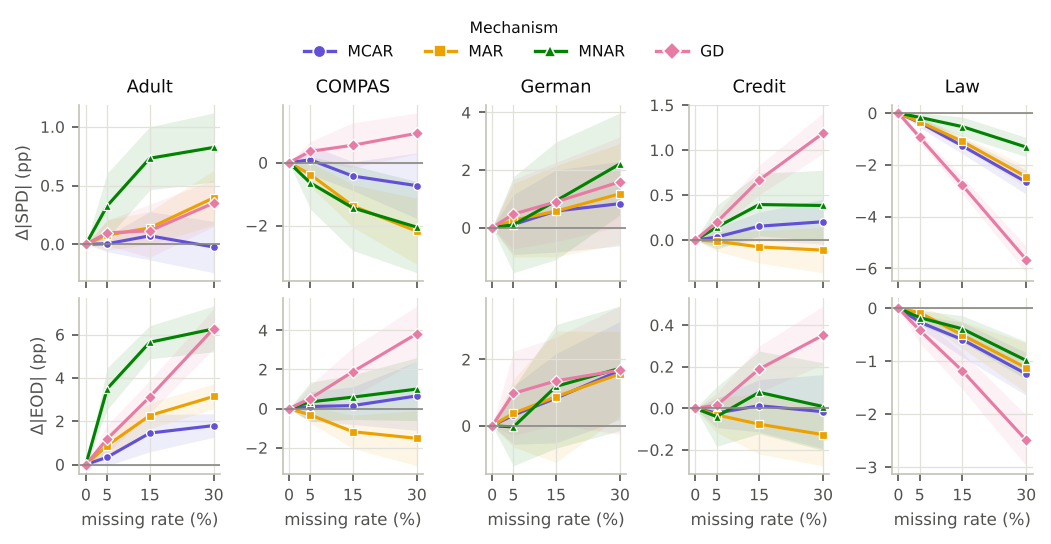

In [36]:
def fig_rate(d_lr: pd.DataFrame, path: Path):
    metrics = [("d_p_spd", "Δ|SPD| (pp)"), ("d_p_eod", "Δ|EOD| (pp)")]
    fig, axes = plt.subplots(2, 5, figsize=(7.2, 3.6), sharex=True)
    for row, (metric, ylabel) in enumerate(metrics):
        for col, ds in enumerate(DATASETS):
            ax = axes[row, col]
            for mech, (c, m) in MECH_STYLE.items():
                sub = d_lr[(d_lr["dataset"] == ds) & (d_lr["mechanism"] == mech)]
                per_seed = sub.groupby(["rate", "seed"])[metric].mean().unstack("rate")
                xs = np.array([0] + [100 * r for r in per_seed.columns])
                mu = np.array([0] + list(100 * per_seed.mean()))
                ci = np.array([0] + [100 * ci95(per_seed[r]) for r in per_seed.columns])
                ax.fill_between(xs, mu - ci, mu + ci, color=c, alpha=0.10, lw=0)
                ax.plot(xs, mu, color=c, lw=1.5, marker=m, ms=3.8, mec="white", mew=0.6)
            ax.axhline(0, color=MUTED, lw=0.8)
            ax.set_xticks([0, 5, 15, 30])
            if row == 0:
                ax.set_title(ds, color=INK)
            if row == 1:
                ax.set_xlabel("missing rate (%)")
            if col == 0:
                ax.set_ylabel(ylabel)
    fig.tight_layout(w_pad=0.4, h_pad=0.6, rect=(0, 0, 1, 0.9))
    fig.legend(handles=legend_handles(MECH_STYLE), loc="upper center", ncol=4, frameon=False,
               bbox_to_anchor=(0.5, 1.0), title="Mechanism", title_fontsize=7.5)
    fig.savefig(path)
    return fig


fig_rate(d1_lr, FIG_DIR / "fig_rate.pdf");

**Figure: RQ1/RQ2 forest plot.** Change in |SPD| and |EOD| at the selected rate for every dataset × mechanism
(rows) and imputer (markers), mean ± 95 % CI over 20 seeds. Right of zero = the gap widened.

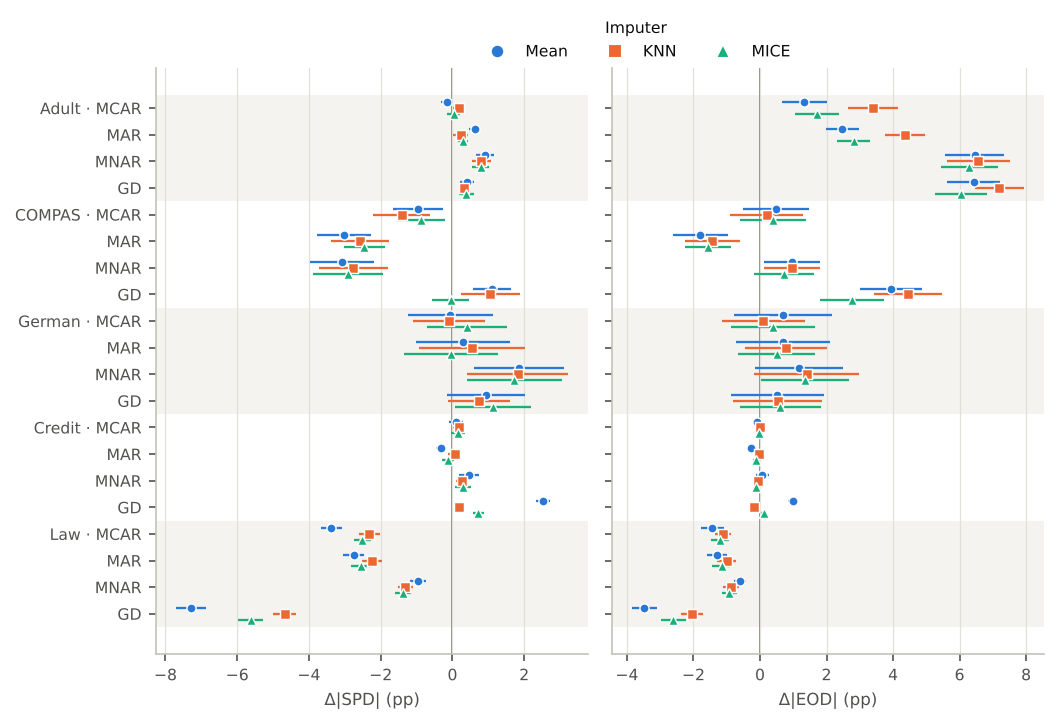

In [37]:
def fig_forest(d_lr: pd.DataFrame, path: Path):
    rows = [(ds, mech) for ds in DATASETS for mech in MECH_ORDER]
    fig, axes = plt.subplots(1, 2, figsize=(7.1, 4.8), sharey=True)
    offs = {"Mean": -0.22, "KNN": 0.0, "MICE": 0.22}
    for ax, (metric, title) in zip(axes, [("d_p_spd", "Δ|SPD| (pp)"), ("d_p_eod", "Δ|EOD| (pp)")]):
        for i, (ds, mech) in enumerate(rows):
            if i % 4 == 0 and (i // 4) % 2 == 0:
                ax.axhspan(i - 0.5, i + 3.5, color="#f4f3f0", zorder=0, lw=0)
            for imp, (c, m) in IMP_STYLE.items():
                x = 100 * d_lr[(d_lr["dataset"] == ds) & (d_lr["mechanism"] == mech)
                               & (d_lr["imputer"] == imp)][metric]
                ax.errorbar(x.mean(), i + offs[imp], xerr=ci95(x), fmt=m, color=c, ms=4.4, mec="white",
                            mew=0.7, elinewidth=1.1, capsize=0, zorder=3)
        ax.axvline(0, color=MUTED, lw=0.9, zorder=1)
        ax.set_xlabel(title)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(range(len(rows)))
    axes[0].set_yticklabels([f"{ds} · {mech}" if mech == "MCAR" else mech for ds, mech in rows])
    axes[0].invert_yaxis()
    fig.legend(handles=[Line2D([0], [0], marker=m, color="none", markerfacecolor=c, markeredgecolor="white",
                               markersize=6.5, label=k) for k, (c, m) in IMP_STYLE.items()],
               loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.6, 1.0), title="Imputer",
               title_fontsize=7.5)
    fig.tight_layout(w_pad=1.0, rect=(0, 0, 1, 0.94))
    fig.savefig(path)
    return fig


fig_forest(main_lr, FIG_DIR / "fig_forest.pdf");

**Figure: RQ3 — who bears the cost?** For group-neutral (MCAR) and group-dependent (GD) missingness at the same
overall rate: change in the true- and false-positive rates of the protected group (red) and the reference group
(grey) relative to complete data, and the signed error (bias) of the imputed values in each group, in units of the
feature's standard deviation (averaged over imputers and 20 seeds).

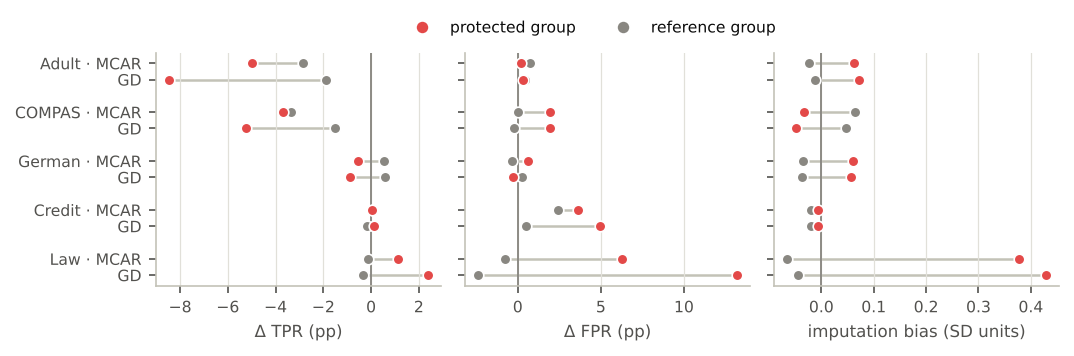

In [38]:
def fig_rq3(gd: pd.DataFrame, mc: pd.DataFrame, path: Path):
    panels = [("d_p_tpr_prot", "d_p_tpr_ref", 100, "Δ TPR (pp)"), ("d_p_fpr_prot", "d_p_fpr_ref", 100, "Δ FPR (pp)"),
              ("bias_prot", "bias_ref", 1, "imputation bias (SD units)")]
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.35), sharey=True)
    ylabels, ypos = [], []
    for k, ds in enumerate(DATASETS):
        for j, (name, frame) in enumerate([("MCAR", mc), ("GD", gd)]):
            y = 3 * k + j
            ylabels.append(f"{ds} · {name}" if j == 0 else "GD")
            ypos.append(y)
            sub = frame[frame["dataset"] == ds]
            for ax, (cp, cr, scale, _) in zip(axes, panels):
                vp, vr = scale * sub[cp].mean(), scale * sub[cr].mean()
                ax.plot([vr, vp], [y, y], color=AXIS, lw=1.2, zorder=1)
                ax.scatter([vr], [y], s=26, color=MUTED, edgecolor="white", lw=0.8, zorder=3)
                ax.scatter([vp], [y], s=26, color=ACCENT, edgecolor="white", lw=0.8, zorder=3)
    for ax, (_, _, _, xlabel) in zip(axes, panels):
        ax.axvline(0, color=MUTED, lw=0.9)
        ax.set_xlabel(xlabel)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(ypos)
    axes[0].set_yticklabels(ylabels)
    axes[0].invert_yaxis()
    handles = [Line2D([0], [0], marker="o", color="none", markerfacecolor=ACCENT, markeredgecolor="white",
                      markersize=6.5, label="protected group"),
               Line2D([0], [0], marker="o", color="none", markerfacecolor=MUTED, markeredgecolor="white",
                      markersize=6.5, label="reference group")]
    fig.tight_layout(w_pad=0.8, rect=(0, 0, 1, 0.92))
    fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.55, 1.0))
    fig.savefig(path)
    return fig


fig_rq3(rq3_gd, rq3_mcar, FIG_DIR / "fig_rq3.pdf");

## 12. Export LaTeX tables for the report
The report `\input`s these files directly, so every number in it comes from this notebook.

In [39]:
def shade(value_pp: float, vmax: float, text: str) -> str:
    """Diverging cell shading: red = gap widened / accuracy lost, blue = gap narrowed / accuracy gained."""
    if not np.isfinite(value_pp) or vmax <= 0:
        return text
    t = float(np.clip(value_pp / vmax, -1, 1))
    pct = int(round(abs(t) * 40))
    if pct < 4:
        return text
    return f"\\cellcolor{{{'widen' if t > 0 else 'narrow'}!{pct}}}{text}"


def write_tex(name: str, body: str):
    (TAB_DIR / f"{name}.tex").write_text(body)

In [40]:
# --- Table: datasets -------------------------------------------------------------------------------------------
# Readable names for the report (the notebook keeps the raw column names).
SHORT_FEATURES = {
    "Adult": "education years, capital gain, capital loss, hours per week",
    "COMPAS": "prior offences; juvenile felony, misdemeanour and other counts",
    "German": "credit amount, instalment rate, years at residence, existing credits",
    "Credit": "credit limit, last repayment status, last bill, last payment",
    "Law": "LSAT, undergraduate GPA, first-year GPA, family income",
}
SHORT_OUTCOME = {"Adult": "income $>$50K", "COMPAS": "no recidivism", "German": "good credit",
                 "Credit": "no default", "Law": "bar passage"}
SHORT_DRIVER = {"Adult": "age", "COMPAS": "age", "German": "credit duration", "Credit": "age", "Law": "school tier"}
APPX = "[!htbp]"          # appendix floats stay where they are defined


def tex_datasets() -> str:
    """Main text: one compact row per dataset (features and MAR drivers are in the appendix table)."""
    lines = [r"\begin{table}[t]", r"\caption{Datasets: favourable outcome and sensitive attributes, given as protected "
             r"group (share). The primary attribute is the target of group-dependent missingness; sensitive attributes "
             r"are not model inputs.}",
             r"\label{tab:datasets}", r"\scriptsize", r"\setlength{\tabcolsep}{2.5pt}", r"\begin{ruledtabular}",
             r"\begin{tabular}{lr>{\raggedright\arraybackslash}p{1.75cm}>{\raggedright\arraybackslash}p{1.85cm}"
             r">{\raggedright\arraybackslash}p{1.85cm}}",
             r"Dataset & Rows & $Y{=}1$ & Primary attribute & Secondary attribute \\ \hline"]
    for ds in DATASETS:
        s_ = SPECS[ds]
        D = s_.data
        (a1, (c1, p1, _)), (a2, (c2, p2, _)) = list(s_.sensitive.items())
        lines.append(f"{ds} & {len(D):,} & {SHORT_OUTCOME[ds]} ({D[s_.target].mean():.0%}) & "
                     f"{a1}: {p1} ({D[c1].mean():.0%}) & {a2}: {p2} ({D[c2].mean():.0%}) \\\\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines).replace("%", r"\%").replace("<=", r"$\le$")


def tex_features() -> str:
    """Appendix: perturbed features and MAR drivers (column names as in the notebook)."""
    lines = [r"\begin{table}" + APPX, r"\caption{Features that receive synthetic missing values (four numeric, "
             r"non-sensitive features per dataset) and the fully observed driver of MAR missingness, with their column "
             r"names in the data.}", r"\label{tab:features}", r"\footnotesize", r"\begin{ruledtabular}",
             r"\begin{tabular}{l>{\raggedright\arraybackslash}p{9.2cm}l}",
             r"Dataset & Perturbed features & MAR driver \\ \hline"]
    for ds in DATASETS:
        s_ = SPECS[ds]
        cols = ", ".join(f.replace("_", r"\_") for f in s_.miss_cols)
        lines.append(f"{ds} & {SHORT_FEATURES[ds]} (\\texttt{{{cols}}}) & {SHORT_DRIVER[ds]} "
                     f"(\\texttt{{{s_.mar_driver.replace('_', chr(92) + '_')}}}) \\\\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines)


write_tex("tab_features", tex_features())
write_tex("tab_datasets", tex_datasets())

# --- Table: realised missing rates ----------------------------------------------------------------------------
def tex_realised(d_lr: pd.DataFrame) -> str:
    g = d_lr.groupby(["mechanism", "rate"])
    lines = [r"\begin{table}" + APPX, r"\caption{Realised share of removed values in the perturbed features (training "
             r"split, mean $\pm$ SD over datasets, seeds and imputers, \%). Last row: protected / reference group "
             r"under GD.}", r"\label{tab:realised}", r"\footnotesize", r"\begin{ruledtabular}", r"\begin{tabular}{lccc}",
             r"Mechanism & 5\% & 15\% & 30\% \\ \hline"]
    for mech in MECH_ORDER:
        cells = [f"${100 * g.get_group((mech, r))['real_rate_tr'].mean():.1f}\\pm"
                 f"{100 * g.get_group((mech, r))['real_rate_tr'].std():.1f}$" for r in RATES]
        lines.append(f"{mech} & " + " & ".join(cells) + r" \\")
    cells = [f"{100 * g.get_group(('GD', r))['real_rate_prot'].mean():.1f} / "
             f"{100 * g.get_group(('GD', r))['real_rate_ref'].mean():.1f}" for r in RATES]
    lines.append(r"\quad GD prot./ref. & " + " & ".join(cells) + r" \\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines)


write_tex("tab_realised", tex_realised(d1_lr))

# --- Table: rate study (visual, per dataset x mechanism) ---------------------------------------------------------
def tex_rate_table(tabs: dict) -> str:
    vmax = {v: max(1e-9, 100 * tabs[v]["mean"].abs().max()) for v in tabs}
    lines = [r"\begin{table*}" + APPX,
             r"\caption{Rate study (Stage 1, logistic regression, primary attribute): change relative to complete "
             r"data in percentage points, averaged over the three imputers within each seed, mean $\pm$ SD over 10 "
             r"seeds; $^\ast$ Wilcoxon BH $q<0.05$ (over the whole table). Red: gap widened or accuracy lost; blue: "
             r"gap narrowed.}",
             r"\label{tab:rate}", r"\scriptsize", r"\setlength{\tabcolsep}{2.2pt}", r"\begin{ruledtabular}",
             r"\begin{tabular}{ll" + "c" * 9 + "}",
             r" & & \multicolumn{3}{c}{$\Delta\abs{\SPD}$} & \multicolumn{3}{c}{$\Delta\abs{\EOD}$} & "
             r"\multicolumn{3}{c}{$\Delta$Accuracy} \\",
             r"Dataset & Mech. & 5\% & 15\% & 30\% & 5\% & 15\% & 30\% & 5\% & 15\% & 30\% \\ \hline"]
    for ds in DATASETS:
        for k, mech in enumerate(MECH_ORDER):
            cells = []
            for v in ("d_p_spd", "d_p_eod", "d_acc"):
                for r in RATES:
                    row = tabs[v].loc[(ds, mech, r)]
                    m_pp, s_pp = 100 * row["mean"], 100 * row["sd"]
                    txt = f"${m_pp:+.1f}\\pm{s_pp:.1f}$" + ("$^\\ast$" if row["sig"] else "")
                    cells.append(shade(-m_pp if v == "d_acc" else m_pp, vmax[v], txt))
            lines.append(f"{ds if k == 0 else ''} & {mech} & " + " & ".join(cells) + r" \\")
        if ds != DATASETS[-1]:
            lines.append(r"\hline")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table*}"]
    return "\n".join(lines)


write_tex("tab_rate", tex_rate_table(RATE_TABLES))


def tex_rate_summary(S: pd.DataFrame, chosen: float) -> str:
    reached = bool((S["share_detected"] >= 0.5).any())
    rule = (r"the lowest rate reaching 50\% is selected ($\star$)" if reached else
            r"no rate reached 50\%, so the most sensitive rate ($\star$) is used")
    lines = [r"\begin{table}[t]", r"\caption{Sensitivity of the experiment at each rate (180 paired tests per rate, "
             r"BH-adjusted). The selection rule asks for at least 50\% detected changes and a mean accuracy loss "
             r"below 2\,pp; " + rule + r" (Sec.~\ref{sec:rate-rule}). $p{<}0.05$: share of tests significant "
             r"before correction (5\% expected by chance). Det.: share detected after BH correction ($q<0.05$); "
             r"$\uparrow$/$\downarrow$: detected changes that widened/narrowed a gap; Med.\ $\abs{\Delta}$: median "
             r"absolute change (pp); SNR: median $\abs{\text{mean}}/\text{SD}$ of the paired change.}",
             r"\label{tab:rate-summary}", r"\scriptsize", r"\setlength{\tabcolsep}{2.2pt}",
             r"\begin{ruledtabular}", r"\begin{tabular}{lcccccc}",
             r"Rate & Det. & $p{<}0.05$ & $\uparrow$/$\downarrow$ & Med.\ $\abs{\Delta}$ & SNR & "
             r"$\Delta$Acc (pp) \\ \hline"]
    for r, row in S.iterrows():
        mark = r" $\star$" if np.isclose(r, chosen) else ""
        lines.append(f"{100 * r:.0f}\\%{mark} & {100 * row['share_detected']:.0f}\\% & "
                     f"{100 * row['share_nominal']:.0f}\\% & {int(row['widened'])}/{int(row['narrowed'])} & "
                     f"{row['median_abs_change_pp']:.2f} & {row['median_snr']:.2f} & "
                     f"${row['mean_d_acc_pp']:+.2f}$ \\\\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines)


write_tex("tab_rate_summary", tex_rate_summary(rate_summary, CHOSEN_RATE))

# --- Table: complete-data baseline --------------------------------------------------------------------------------
def tex_baseline(B: pd.DataFrame) -> str:
    lines = [r"\begin{table}" + APPX, r"\caption{Complete-data baseline (logistic regression, mean $\pm$ SD over 20 "
             r"seeds). Negative SPD/EOD: the protected group is disadvantaged; DIR $<0.8$ violates the four-fifths "
             r"rule.}", r"\label{tab:baseline}",
             r"\scriptsize", r"\setlength{\tabcolsep}{3pt}", r"\begin{ruledtabular}", r"\begin{tabular}{llcccc}",
             r"Dataset & Attribute & Acc. & SPD & EOD & DIR \\ \hline"]
    for ds in DATASETS:
        sub = B[B["dataset"] == ds]
        for k, (_, r) in enumerate(sub.iterrows()):
            acc = f"{r['acc_mean']:.3f}" if k == 0 else ""
            lines.append(f"{ds if k == 0 else ''} & {r['attribute']} & {acc} & "
                         f"${r['spd_mean']:+.3f}\\pm{r['spd_sd']:.3f}$ & ${r['eod_mean']:+.3f}\\pm{r['eod_sd']:.3f}$ & "
                         f"{r['dir_mean']:.2f} \\\\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines)


write_tex("tab_baseline", tex_baseline(baseline))

# --- Table: overall (THE mechanism x imputer comparison; results section only) --------------------------------------
def tex_overall(A: pd.DataFrame, T: pd.DataFrame | None, label: str, caption: str, pos: str = "[t]") -> str:
    """Per-dataset accuracy, |SPD| and |EOD| for the baseline and every mechanism x imputer, shaded by the change."""
    mean = A.xs("mean", axis=1, level=1)
    lines = [r"\begin{table*}" + pos, f"\\caption{{{caption}}}", f"\\label{{{label}}}", r"\scriptsize",
             r"\setlength{\tabcolsep}{2.4pt}", r"\begin{ruledtabular}", r"\begin{tabular}{ll" + "ccc" * 5 + "}",
             r" & & " + " & ".join(f"\\multicolumn{{3}}{{c}}{{{ds}}}" for ds in DATASETS) + r" \\",
             r"Mech. & Imp. & " + " & ".join([r"Acc & $\abs{\SPD}$ & $\abs{\EOD}$"] * 5) + r" \\ \hline"]
    conds = [("Complete", "Complete")] + [(m, i) for m in MECH_ORDER for i in IMP_ORDER]
    vmax = {}
    for col in ("acc", "abs_spd", "abs_eod"):
        diffs = [100 * (mean.loc[(ds, m, i), col] - mean.loc[(ds, "Complete", "Complete"), col])
                 for ds in DATASETS for m, i in conds[1:]]
        vmax[col] = max(1e-9, np.max(np.abs(diffs)))
    metric_of = {"acc": "d_acc", "abs_spd": "d_p_spd", "abs_eod": "d_p_eod"}
    for mech, imp in conds:
        cells = []
        for ds in DATASETS:
            for col in ("acc", "abs_spd", "abs_eod"):
                val = mean.loc[(ds, mech, imp), col]
                txt = f"{val:.3f}"
                if mech != "Complete":
                    diff = 100 * (val - mean.loc[(ds, "Complete", "Complete"), col])
                    if T is not None:
                        t = T[(T["dataset"] == ds) & (T["mechanism"] == mech) & (T["imputer"] == imp)
                              & (T["metric"] == metric_of[col])]
                        if len(t) and bool(t["sig"].iloc[0]):
                            txt += r"$^\ast$"
                    txt = shade(-diff if col == "acc" else diff, vmax[col], txt)
                cells.append(txt)
        lab_m = mech if imp in ("Mean", "Complete") else ""
        lines.append(f"{lab_m} & {'--' if imp == 'Complete' else imp} & " + " & ".join(cells) + r" \\")
        if imp in ("Complete", "MICE") and mech != MECH_ORDER[-1]:
            lines.append(r"\hline")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table*}"]
    return "\n".join(lines)


OVERALL_CAPTION = (r"Performance and fairness by missingness mechanism and imputation method at the selected rate "
                   r"(logistic regression, primary attribute; mean over 20 seeds). ``Complete'' is the baseline "
                   r"without missing values on the same splits. $^\ast$ significant paired change vs.\ complete data "
                   r"(Wilcoxon, BH $q<0.05$ over the table). Red: gap wider or accuracy lower than complete data; blue: "
                   r"gap narrower.")
write_tex("tab_overall", tex_overall(overall_abs, rq_tests, "tab:overall", OVERALL_CAPTION))
hgb_tests_all = test_table(main_hgb, ["dataset", "mechanism", "imputer"], ["d_p_spd", "d_p_eod", "d_acc"])
write_tex("tab_overall_hgb", tex_overall(hgb_abs, hgb_tests_all, "tab:overall-hgb", OVERALL_CAPTION.replace(
    "logistic regression", "gradient boosting, HGB").replace("Performance and fairness", "Robustness check: "
                                                             "performance and fairness"), pos=APPX))

# --- Table: RQ1 and RQ2 rank summaries -----------------------------------------------------------------------------
def tex_ranks(F_summary: pd.DataFrame, levels, label, caption) -> str:
    lines = [r"\begin{table}[t]", f"\\caption{{{caption}}}", f"\\label{{{label}}}", r"\scriptsize",
             r"\setlength{\tabcolsep}{3pt}", r"\begin{ruledtabular}",
             r"\begin{tabular}{lc" + "c" * len(levels) + "|" + "c" * len(levels) + "}",
             r" & & \multicolumn{" + str(len(levels)) + r"}{c|}{Average rank} & \multicolumn{" + str(len(levels))
             + r"}{c}{Mean $\abs{\Delta}$ (pp)} \\",
             r"Gap & Signif. & " + " & ".join(levels) + " & " + " & ".join(levels) + r" \\ \hline"]
    for metric, r in F_summary.iterrows():
        name = r"$\abs{\SPD}$" if metric.endswith("spd") else r"$\abs{\EOD}$"
        lines.append(f"{name} & {int(r['significant'])}/{int(r['blocks'])} & "
                     + " & ".join(f"{r[f'avg_rank_{l}']:.2f}" for l in levels) + " & "
                     + " & ".join(f"{r[f'mean_abs_{l}_pp']:.2f}" for l in levels) + r" \\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines)


def tex_rq12(F1: pd.DataFrame, F2: pd.DataFrame) -> str:
    """RQ1 (mechanisms) and RQ2 (imputers) Friedman summaries in one compact table."""
    lines = [r"\begin{table}[t]", r"\caption{RQ1 and RQ2: Friedman tests within blocks (20 seeds, BH-adjusted; Sig.: "
             r"blocks with $q<0.05$), average rank (1 = smallest gap after imputation) and mean absolute change. RQ1 "
             r"compares mechanisms within 15 dataset $\times$ imputer blocks, RQ2 imputers within 20 dataset $\times$ "
             r"mechanism blocks.}", r"\label{tab:rq12}", r"\scriptsize", r"\setlength{\tabcolsep}{3pt}",
             r"\begin{ruledtabular}", r"\begin{tabular}{lcccc|ccc}",
             r" & Sig. & \multicolumn{3}{c|}{Average rank} & \multicolumn{3}{c}{Mean $\abs{\Delta}$ (pp)} \\ \hline"]
    for tag, F, levels in (("RQ1", F1, ["MCAR", "MAR", "MNAR"]), ("RQ2", F2, IMP_ORDER)):
        lines.append(f"\\emph{{{tag}}} & & " + " & ".join(levels) + " & " + " & ".join(levels) + r" \\")
        for metric, r in F.iterrows():
            name = r"\quad$\abs{\SPD}$" if metric.endswith("spd") else r"\quad$\abs{\EOD}$"
            lines.append(f"{name} & {int(r['significant'])}/{int(r['blocks'])} & "
                         + " & ".join(f"{r[f'avg_rank_{l}']:.2f}" for l in levels) + " & "
                         + " & ".join(f"{r[f'mean_abs_{l}_pp']:.2f}" for l in levels) + r" \\")
        if tag == "RQ1":
            lines.append(r"\hline")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines)


write_tex("tab_rq12", tex_rq12(rq1_summary, rq2_summary))

# --- Table: RQ3 (GD - MCAR) ------------------------------------------------------------------------------------------
def tex_rq3(T: pd.DataFrame) -> str:
    """Main text: GD minus MCAR at the same overall rate, per dataset and imputer."""
    lines = [r"\begin{table}[t]", r"\caption{RQ3: group-dependent (GD) minus group-neutral (MCAR) missingness at the "
             r"same overall rate (pp; mean over 20 paired seeds; $^\ast$ Wilcoxon BH $q<0.05$). Red: GD widens the gap "
             r"more; blue: GD narrows it.}", r"\label{tab:rq3}", r"\scriptsize", r"\setlength{\tabcolsep}{2.4pt}",
             r"\begin{ruledtabular}", r"\begin{tabular}{lccc|ccc}",
             r" & \multicolumn{3}{c|}{$\Delta\abs{\SPD}$} & \multicolumn{3}{c}{$\Delta\abs{\EOD}$} \\",
             r"Dataset & Mean & KNN & MICE & Mean & KNN & MICE \\ \hline"]
    vmax = max(1e-9, 100 * T[T["metric"].isin(["d_p_spd", "d_p_eod"])]["mean"].abs().max())
    for ds in DATASETS:
        cells = []
        for v in ("d_p_spd", "d_p_eod"):
            for imp in IMP_ORDER:
                r = T[(T["dataset"] == ds) & (T["imputer"] == imp) & (T["metric"] == v)].iloc[0]
                txt = f"${100 * r['mean']:+.2f}$" + ("$^\\ast$" if r["sig"] else "")
                cells.append(shade(100 * r["mean"], vmax, txt))
        lines.append(f"{ds} & " + " & ".join(cells) + r" \\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines)


def tex_rq3_detail(dec: pd.DataFrame) -> str:
    """Appendix: per-group TPR/FPR changes and imputation error under MCAR and GD."""
    lines = [r"\begin{table}" + APPX, r"\caption{RQ3 decomposition: change in the protected / reference group's TPR "
             r"and FPR relative to complete data (pp), normalised RMSE and signed bias (feature SDs) of their imputed "
             r"values, under MCAR and GD at the same overall rate (logistic regression, mean over imputers and 20 "
             r"seeds).}", r"\label{tab:rq3-detail}", r"\footnotesize", r"\setlength{\tabcolsep}{3pt}",
             r"\begin{ruledtabular}", r"\begin{tabular}{lcccccccc}",
             r" & \multicolumn{2}{c}{$\Delta$TPR prot./ref.} & \multicolumn{2}{c}{$\Delta$FPR prot./ref.} & "
             r"\multicolumn{2}{c}{NRMSE prot./ref.} & \multicolumn{2}{c}{Bias prot./ref.} \\",
             r"Dataset & MCAR & GD & MCAR & GD & MCAR & GD & MCAR & GD \\ \hline"]
    for ds in DATASETS:
        cells = []
        for col_p, col_r in (("d_p_tpr_prot", "d_p_tpr_ref"), ("d_p_fpr_prot", "d_p_fpr_ref")):
            for mech in ("MCAR", "GD"):
                r = dec.loc[(ds, mech)]
                cells.append(f"${100 * r[col_p]:+.1f}/{100 * r[col_r]:+.1f}$")
        for mech in ("MCAR", "GD"):
            r = dec.loc[(ds, mech)]
            cells.append(f"{r['nrmse_prot']:.2f}/{r['nrmse_ref']:.2f}")
        for mech in ("MCAR", "GD"):
            r = dec.loc[(ds, mech)]
            cells.append(f"${r['bias_prot']:+.2f}/{r['bias_ref']:+.2f}$")
        lines.append(f"{ds} & " + " & ".join(cells) + r" \\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines)


write_tex("tab_rq3_detail", tex_rq3_detail(decomp))
write_tex("tab_rq3", tex_rq3(rq3_tests))

# --- Supplementary tables (report appendix) ----------------------------------------------------------------------------------------------
def tex_supp(S: pd.DataFrame, noise_tab: pd.DataFrame) -> str:
    lines = [r"\begin{table*}" + APPX, r"\caption{Supplementary analyses at the selected rate (logistic regression, mean "
             r"over imputers and 20 seeds, pp; $^\ast$ BH $q<0.05$): change of the secondary attribute's $\abs{\SPD}$, "
             r"of the largest selection-rate gap between the four intersectional subgroups and of the calibration "
             r"gap between groups. Last columns: seed-to-seed SD of the complete-data gaps (noise floor).}",
             r"\label{tab:supp}", r"\scriptsize", r"\setlength{\tabcolsep}{2.6pt}",
             r"\begin{ruledtabular}", r"\begin{tabular}{l" + "cccc" * 3 + "cc}",
             r" & \multicolumn{4}{c}{$\Delta\abs{\SPD}$, secondary attribute} & \multicolumn{4}{c}{$\Delta$ "
             r"intersectional SR gap} & \multicolumn{4}{c}{$\Delta$ calibration gap} & \multicolumn{2}{c}{noise SD} \\",
             r"Dataset & MCAR & MAR & MNAR & GD & MCAR & MAR & MNAR & GD & MCAR & MAR & MNAR & GD & $\abs{\SPD}$ & "
             r"$\abs{\EOD}$ \\ \hline"]
    for ds in DATASETS:
        cells = []
        for v in ("d_s_spd", "d_int_sr_gap", "d_p_cal"):
            for mech in MECH_ORDER:
                r = S[(S["dataset"] == ds) & (S["mechanism"] == mech) & (S["metric"] == v)].iloc[0]
                cells.append(f"${100 * r['mean']:+.2f}$" + ("$^\\ast$" if r["sig"] else ""))
        cells += [f"{noise_tab.loc[ds, 'sd |SPD| (pp)']:.2f}", f"{noise_tab.loc[ds, 'sd |EOD| (pp)']:.2f}"]
        lines.append(f"{ds} & " + " & ".join(cells) + r" \\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table*}"]
    return "\n".join(lines)


write_tex("tab_supp", tex_supp(supp, noise))


def tex_cost(C: pd.DataFrame) -> str:
    wins = C.groupby(["scenario", "best_imputer"]).size().unstack(fill_value=0).reindex(columns=IMP_ORDER,
                                                                                       fill_value=0)
    lines = [r"\begin{table}" + APPX, r"\caption{Cost-sensitive choice of imputer: number of dataset $\times$ mechanism "
             r"cells (out of 20) in which each imputer minimises the expected cost $(c_{FP}FP+c_{FN}FN)/n+\lambda"
             r"\abs{\SPD}$ (logistic regression, 20 seeds).}", r"\label{tab:cost}", r"\footnotesize",
             r"\begin{ruledtabular}", r"\begin{tabular}{lccc}", r"Scenario & Mean & KNN & MICE \\ \hline"]
    for sc in SCENARIOS:
        r = wins.loc[sc]
        name = sc.replace("λ", r"$\lambda$")
        lines.append(name + " & " + " & ".join(str(int(r[i])) for i in IMP_ORDER) + r" \\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines)


write_tex("tab_cost", tex_cost(costs))


def tex_fi(F: pd.DataFrame) -> str:
    lines = [r"\begin{table}" + APPX, r"\caption{Feature-importance shift (logistic regression): share of the total "
             r"$\abs{\text{coefficient}}$ mass on the four perturbed features with complete data and after "
             r"imputation (mean over imputers and 20 seeds; $^\ast$ BH $q<0.05$ for the change).}",
             r"\label{tab:fi}", r"\footnotesize", r"\begin{ruledtabular}", r"\begin{tabular}{lccccc}",
             r"Dataset & Complete & MCAR & MAR & MNAR & GD \\ \hline"]
    for ds in DATASETS:
        base_w = F.loc[(ds, "MCAR"), "w_perturbed_base"]
        cells = [f"{base_w:.3f}"]
        for m in MECH_ORDER:
            star = r"$^\ast$" if F.loc[(ds, m), "sig"] else ""
            cells.append(f"{F.loc[(ds, m), 'w_perturbed']:.3f}" + star)
        lines.append(f"{ds} & " + " & ".join(cells) + r" \\")
    lines += [r"\end{tabular}", r"\end{ruledtabular}", r"\end{table}"]
    return "\n".join(lines)


write_tex("tab_fi", tex_fi(fi_tab))
sorted(p.name for p in TAB_DIR.glob("*.tex"))

['numbers.tex',
 'runtime_hours.tex',
 'tab_baseline.tex',
 'tab_cost.tex',
 'tab_datasets.tex',
 'tab_features.tex',
 'tab_fi.tex',
 'tab_overall.tex',
 'tab_overall_hgb.tex',
 'tab_rate.tex',
 'tab_rate_summary.tex',
 'tab_realised.tex',
 'tab_rq1.tex',
 'tab_rq12.tex',
 'tab_rq2.tex',
 'tab_rq3.tex',
 'tab_rq3_detail.tex',
 'tab_supp.tex']

Compute budget actually used (sum of the imputation and model-fitting times logged by every task):

In [41]:
_all = pd.concat([stage1, stage2], ignore_index=True)
cpu_hours = (_all.loc[_all["model"] == "LR", "t_impute"].sum() + _all["t_model"].sum()) / 3600
(TAB_DIR / "runtime_hours.tex").write_text(f"{cpu_hours:.1f}")
print(f"Total compute: {cpu_hours:.2f} CPU-hours over {len(_all):,} model fits")

Total compute: 4.27 CPU-hours over 5,000 model fits


### Numbers quoted in the text of the report
Every number that appears in the prose of the report is written here as a LaTeX macro (`tables/numbers.tex`), so
the text cannot drift away from the results.

In [42]:
def latex_numbers() -> str:
    N = {}

    def put(name, value):
        assert name.isalpha(), name
        N[name] = value

    word = {0.05: "Five", 0.15: "Fifteen", 0.30: "Thirty"}
    # baseline
    for _, r in baseline.iterrows():
        role = "p" if r["attribute"] == SPECS[r["dataset"]].primary else "s"
        tag = r["dataset"] + ("" if role == "p" else "Sec")
        put(f"num{tag}BaseSPD", f"{r['spd_mean']:+.3f}")
        put(f"num{tag}BaseEOD", f"{r['eod_mean']:+.3f}")
        put(f"num{tag}BaseEODpp", f"{100 * abs(r['eod_mean']):.1f}")
        put(f"num{tag}BaseSPDpp", f"{100 * abs(r['spd_mean']):.1f}")
        put(f"num{tag}BaseDIR", f"{r['dir_mean']:.2f}")
        if role == "p":
            put(f"num{tag}BaseAcc", f"{r['acc_mean']:.3f}")
    put("numDIRbelow", str(int((baseline["dir_mean"] < 0.8).sum())))
    put("numDIRpairs", str(len(baseline)))
    # rate study
    for rate, row in rate_summary.iterrows():
        w = word[round(rate, 2)]
        put(f"numRateDetect{w}", f"{100 * row['share_detected']:.0f}")
        put(f"numRateNominal{w}", f"{100 * row['share_nominal']:.0f}")
        put(f"numRateAcc{w}", f"{row['mean_d_acc_pp']:+.2f}")
        put(f"numRateWiden{w}", str(int(row["widened"])))
        put(f"numRateNarrow{w}", str(int(row["narrowed"])))
        put(f"numRatePone{w}", str(int((rate_tests.loc[rate_tests["rate"] == rate, "p"] < 0.01).sum())))
    put("numRateTests", str(int(rate_summary["tests"].iloc[0])))
    put("numChosenRate", f"{100 * CHOSEN_RATE:.0f}")
    # Stage 1 (10 seeds) at 30%, imputer-averaged: the same numbers as the 30% column of the rate-study table (report Table A4)
    for v, nm in (("d_p_spd", "spd"), ("d_p_eod", "eod"), ("d_acc", "acc")):
        for (ds, mech, rate), r in RATE_TABLES[v].iterrows():
            if np.isclose(rate, 0.30):
                put(f"numRS{ds}{mech}{nm}", f"{100 * r['mean']:+.1f}")
    for ds, g in stage1[(stage1["mechanism"] == "Complete") & (stage1["model"] == "LR")].groupby("dataset"):
        put(f"numRS{ds}BaseEODpp", f"{100 * g['p_eod'].abs().mean():.1f}")
        put(f"numRS{ds}BaseSPDpp", f"{100 * g['p_spd'].abs().mean():.1f}")
    law = RATE_TABLES["d_p_spd"].loc["Law"]
    law = law[np.isclose(law.index.get_level_values("rate"), 0.30)]["mean"]
    put("numRSLawSPDhi", f"{100 * law.max():+.1f}")
    put("numRSLawSPDlo", f"{100 * law.min():+.1f}")
    # per dataset x mechanism, imputer-averaged, at the selected rate (pp)
    eff = main_lr.groupby(["dataset", "mechanism", "seed"])[["d_p_spd", "d_p_eod", "d_acc", "d_s_spd", "d_s_eod"]] \
        .mean().groupby(level=[0, 1]).mean()
    for (ds, mech), r in eff.iterrows():
        for col, nm in (("d_p_spd", "spd"), ("d_p_eod", "eod"), ("d_acc", "acc"), ("d_s_spd", "sspd"),
                        ("d_s_eod", "seod")):
            put(f"num{ds}{mech}{nm}", f"{100 * r[col]:+.1f}")
    # per dataset x mechanism x imputer (pp) for the gaps
    for (ds, mech, imp), g in main_lr.groupby(["dataset", "mechanism", "imputer"]):
        for col, nm in (("d_p_spd", "spd"), ("d_p_eod", "eod")):
            put(f"num{ds}{mech}{imp}{nm}", f"{100 * g[col].mean():+.1f}")
    acc_cells = main_lr.groupby(["dataset", "mechanism", "imputer"])["d_acc"].mean() * 100
    put("numAccLossMin", f"{acc_cells.max():+.1f}")
    put("numAccLossMax", f"{acc_cells.min():+.1f}")
    # significance counts at the selected rate (60 conditions)
    for metric, nm in (("d_p_spd", "spd"), ("d_p_eod", "eod"), ("d_acc", "acc")):
        t = rq_tests[rq_tests["metric"] == metric]
        put(f"numSig{nm}Widen", str(int((t["sig"] & (t["mean"] > 0)).sum())))
        put(f"numSig{nm}Narrow", str(int((t["sig"] & (t["mean"] < 0)).sum())))
        put("numConditions", str(len(t)))
    # RQ1 and RQ2
    for summ, levels, tag in ((rq1_summary, ["MCAR", "MAR", "MNAR"], "One"), (rq2_summary, IMP_ORDER, "Two")):
        for metric, r in summ.iterrows():
            nm = "spd" if metric.endswith("spd") else "eod"
            put(f"numRQ{tag}Sig{nm}", str(int(r["significant"])))
            put(f"numRQ{tag}Blocks", str(int(r["blocks"])))
            for l in levels:
                put(f"numRank{l}{nm}", f"{r[f'avg_rank_{l}']:.2f}")
                put(f"numMag{l}{nm}", f"{r[f'mean_abs_{l}_pp']:.2f}")
    for _, r in rq2_overall.iterrows():
        nm = {"d_p_spd": "spd", "d_p_eod": "eod", "d_acc": "acc"}[r["value"]]
        put(f"numRQTwoP{nm}", f"{r['p']:.3f}")
        for l in IMP_ORDER:
            put(f"numRQTwoRankAll{l}{nm}", f"{r[f'avg_rank_{l}']:.2f}")
    put("numRQTwoCD", f"{rq2_overall['nemenyi_cd'].iloc[0]:.2f}")
    put("numRQTwoBlocksAll", str(int(rq2_overall["blocks"].iloc[0])))
    nr = main_lr.groupby("imputer")["nrmse_all"].mean()
    for l in IMP_ORDER:
        put(f"numNRMSE{l}", f"{nr[l]:.2f}")
    # RQ3
    for metric, nm in (("d_p_spd", "spd"), ("d_p_eod", "eod"), ("d_s_spd", "sspd"), ("d_s_eod", "seod")):
        t = rq3_tests[rq3_tests["metric"] == metric]
        put(f"numGD{nm}Widen", str(int((t["sig"] & (t["mean"] > 0)).sum())))
        put(f"numGD{nm}Narrow", str(int((t["sig"] & (t["mean"] < 0)).sum())))
        put("numGDblocks", str(len(t)))
    for (ds, mech), r in decomp.iterrows():
        for col, nm in (("d_p_tpr_prot", "tprProt"), ("d_p_tpr_ref", "tprRef"), ("d_p_fpr_prot", "fprProt"),
                        ("d_p_fpr_ref", "fprRef"), ("d_p_sr_prot", "srProt"), ("d_p_sr_ref", "srRef"),
                        ("d_p_acc_prot", "accProt"), ("d_p_acc_ref", "accRef")):
            put(f"num{ds}{mech}{nm}", f"{100 * r[col]:+.1f}")
        for col, nm in (("bias_prot", "biasProt"), ("bias_ref", "biasRef"), ("nrmse_prot", "nrmseProt"),
                        ("nrmse_ref", "nrmseRef")):
            put(f"num{ds}{mech}{nm}", f"{r[col]:+.2f}" if col.startswith("bias") else f"{r[col]:.2f}")
    # robustness
    for _, r in robustness.iterrows():
        nm = {"d_p_spd": "spd", "d_p_eod": "eod", "d_acc": "acc"}[r["metric"]]
        put(f"numHGBrho{nm}", f"{r['spearman_rho']:.2f}")
        put(f"numHGBsign{nm}", f"{100 * r['sign_agreement']:.0f}")
    for ds, r in noise.iterrows():
        put(f"num{ds}NoiseSPD", f"{r['sd |SPD| (pp)']:.2f}")
        put(f"num{ds}NoiseEOD", f"{r['sd |EOD| (pp)']:.2f}")
    stacked = pd.concat({"SPD": noise["sd |SPD| (pp)"], "EOD": noise["sd |EOD| (pp)"]})   # (metric, dataset)
    (m_lo, d_lo), (m_hi, d_hi) = stacked.idxmin(), stacked.idxmax()
    put("numNoiseMin", f"{stacked.min():.2f}")
    put("numNoiseMax", f"{stacked.max():.2f}")
    put("numNoiseMinWhere", f"{d_lo}, $\\abs{{\\{m_lo}}}$")
    put("numNoiseMaxWhere", f"{d_hi}, $\\abs{{\\{m_hi}}}$")
    put("numCostStable", f"{100 * stable:.0f}")
    put("numFIrho", f"{corr_fi.statistic:.2f}")
    put("numFIp", f"{corr_fi.pvalue:.3f}")
    put("numCPUhours", f"{cpu_hours:.1f}")
    put("numSeedsMain", str(int(main_lr["seed"].nunique())))
    for k, v in list(N.items()):                      # unsigned twins, e.g. "drops by \\numXAbs pp"
        if re.fullmatch(r"[+-]\d+(\.\d+)?", v):
            N[k + "Abs"] = v.lstrip("+-")
    return "\n".join(f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in sorted(N.items())) + "\n"


(TAB_DIR / "numbers.tex").write_text(latex_numbers())
print((TAB_DIR / "numbers.tex").read_text()[:1500])

\newcommand{\numAccLossMax}{-4.5}
\newcommand{\numAccLossMaxAbs}{4.5}
\newcommand{\numAccLossMin}{+0.3}
\newcommand{\numAccLossMinAbs}{0.3}
\newcommand{\numAdultBaseAcc}{0.847}
\newcommand{\numAdultBaseDIR}{0.31}
\newcommand{\numAdultBaseEOD}{-0.086}
\newcommand{\numAdultBaseEODAbs}{0.086}
\newcommand{\numAdultBaseEODpp}{8.6}
\newcommand{\numAdultBaseSPD}{-0.182}
\newcommand{\numAdultBaseSPDAbs}{0.182}
\newcommand{\numAdultBaseSPDpp}{18.2}
\newcommand{\numAdultGDKNNeod}{+7.2}
\newcommand{\numAdultGDKNNeodAbs}{7.2}
\newcommand{\numAdultGDKNNspd}{+0.3}
\newcommand{\numAdultGDKNNspdAbs}{0.3}
\newcommand{\numAdultGDMICEeod}{+6.0}
\newcommand{\numAdultGDMICEeodAbs}{6.0}
\newcommand{\numAdultGDMICEspd}{+0.4}
\newcommand{\numAdultGDMICEspdAbs}{0.4}
\newcommand{\numAdultGDMeaneod}{+6.4}
\newcommand{\numAdultGDMeaneodAbs}{6.4}
\newcommand{\numAdultGDMeanspd}{+0.4}
\newcommand{\numAdultGDMeanspdAbs}{0.4}
\newcommand{\numAdultGDacc}{-1.0}
\newcommand{\numAdultGDaccAbs}{1.0}
\newcommand{\numAdultG